# Stock markets and macro fundamentals: a cointegration analysis of WIG20 and S&P 500 (2008–2024)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igazys/wig20-sp500/blob/main/WIG20_SP500_cointegration.ipynb)

> **Research question:** Do stock indices share long-run equilibrium relationships with real macroeconomic fundamentals, with economic policy uncertainty and with each other, and how do structural shocks change these relationships?

### Overview and motivation

Stock prices and macro fundamentals like GDP, unemployment, inflation and exchange rates all follow stochastic trends. Regressing one such series on another gives high $R^2$ and large t-statistics even when the series are unrelated, which is known as a spurious regression problem (*Granger & Newbold, 1974*).

Cointegration tests (*Engle & Granger, 1987*) keep only the relationships in which the series share a common stochastic trend and cannot drift apart permanently. The project compares an emerging market (Poland, WIG20; emerging under the MSCI classification, although FTSE Russell has classified Poland as developed since 2018) with a developed market (USA, S&P 500) on monthly, quarterly and weekly data for 2008–2024.

### Research hypotheses

| Hypothesis | Statement | Variables | Methods | Supporting literature |
| :--- | :--- | :--- | :--- | :--- |
| **H1** (macro fundamentals) | The main national stock index is cointegrated with domestic macroeconomic variables. | Inflation (CPI), unemployment, short-term rates, GDP | Engle-Granger (1987), Gregory-Hansen (1996), VECM/Johansen (1988)| Chen, Roll & Ross (1986); Fama & Schwert (1977); Bernanke & Kuttner (2005); Panda (2008); Wiśniewski (2014) |
| **H2** (policy uncertainty) | The main national stock index is cointegrated with economic policy uncertainty. | Economic Policy Uncertainty (EPU) index | Single-equation and system cointegration tests | Antonakakis, Chatziantoniou & Filis (2013); Yıldırım & Ince-Yenilmez (2025) |
| **H3** (market interdependence) | The emerging market is linked to, and in the long run depends on, the developed market. | WIG20, S&P 500 (in PLN), USD/PLN | Rolling cointegration, VECM and Granger causality | Aggarwal, Inclan & Leal (1999); Muradoglu, Taskin & Bigan (2000); Sarwar & Khan (2017) |

### Structure of the analysis

1. Unit-root and stationarity tests (Augmented Dickey-Fuller, KPSS, Zivot-Andrews (1992)) check that every series is integrated of order 1, $I(1)$, allowing for a structural break in each series.
2. A naive OLS benchmark in levels shows how often regressions on trending series produce false significance.

* **Part A: Engle-Granger cointegration (no structural break).** This test checks whether the index and the variable share a stable long-run relationship that holds over the whole sample. For every index-variable pair, a long-run regression is estimated by OLS:

  $$y_t = a + b\,x_t + u_t$$

  and its residuals $\hat u_t$ are tested for stationarity with MacKinnon (2010) critical values. Cointegrated pairs are then modelled with error-correction models (ECM), which give the speed of adjustment $\gamma$ and the half-life of deviations:

  $$\Delta y_t = c + \gamma\,\hat u_{t-1} + \phi\,\Delta y_{t-1} + \theta_0\,\Delta x_t + \theta_1\,\Delta x_{t-1} + \varepsilon_t, \qquad \text{half-life} = \frac{\ln 0.5}{\ln(1+\gamma)}$$

* **Part B: Gregory-Hansen cointegration (one unknown structural break).** This test allows the relationship to change once, at a date $\tau$ estimated from the data: a level shift (C), a level shift with trend (C/T), or a regime shift (C/S). This accounts for shocks such as the 2008 financial crisis and COVID-19. With $D_{t\tau} = 1$ for $t \ge \tau$ and 0 otherwise, the regime-shift model is:

  $$y_t = \mu_1 + \mu_2 D_{t\tau} + \beta_1 x_t + \beta_2 x_t D_{t\tau} + u_t$$

  The break date minimises the residual ADF statistic, $ADF^* = \inf_\tau ADF(\tau)$. Pairs cointegrated only with a break are then modelled with ECMs.

* **Part C: comparison.** How the results change once a structural break is allowed.

* **Part D: system cointegration and causality.** Johansen system tests and vector error-correction models (VECM) for each country:

  $$\Delta Y_t = \mu + \alpha\beta^\top Y_{t-1} + \sum_{i=1}^{p-1}\Gamma_i\,\Delta Y_{t-i} + \varepsilon_t$$

  where $\beta$ holds the long-run relations and $\alpha$ the adjustment speeds. Granger (1969) causality between WIG20 and the S&P 500 tests $H_0$: the lags of $x$ add nothing to the forecast of $y$,

  $$\Delta y_t = c + \sum_{i=1}^{p} a_i\,\Delta y_{t-i} + \sum_{i=1}^{p} b_i\,\Delta x_{t-i} + \varepsilon_t, \qquad H_0: b_1 = \dots = b_p = 0$$

  followed by the robustness of the Johansen rank to the deterministic specification (none, constant, linear trend).

* **Part E: robustness to WIG20 mean reversion.**
  * An extended unit-root battery for the indices (ADF, DF-GLS, Phillips-Perron (1988), KPSS, Zivot-Andrews), based on the regression

    $$\Delta y_t = c + \rho\,y_{t-1} + \sum_{i=1}^{k}\delta_i\,\Delta y_{t-i} + \varepsilon_t, \qquad H_0: \rho = 0 \ \text{(unit root)}$$

    where $\rho < 0$ means mean reversion with half-life $\ln 0.5 / \ln(1+\rho)$.
  * Placebo tests of WIG20 against independent random walks ($x_t = x_{t-1} + e_t$) and against the *other* country's macro variables.
  * A Johansen likelihood-ratio test of whether each WIG20 "cointegrating relation" is just WIG20 being stationary on its own, $H_0: \beta = (1, 0)'$:

    $$LR = T\,\ln\frac{1-\lambda^*}{1-\hat\lambda_1} \sim \chi^2(1)$$

  * The ARDL bounds test (Pesaran, Shin & Smith, 2001), valid whether the variables are I(0) or I(1), on the unrestricted error-correction model

    $$\Delta y_t = c + \pi_y\,y_{t-1} + \pi_x\,x_{t-1} + \sum_{i=1}^{p-1}\phi_i\,\Delta y_{t-i} + \sum_{j=0}^{q-1}\theta_j\,\Delta x_{t-j} + \varepsilon_t$$

    with the F-test of $\pi_y = \pi_x = 0$, the degenerate-case checks of McNown, Sam & Goh (2018) (a t-test of $\pi_y = 0$ and a bootstrap test of $\pi_x = 0$), and the long-run coefficient $b = -\pi_x/\pi_y$.

### Data sources

| Series | Frequency | Source |
| :--- | :--- | :--- |
| **S&P 500** | Weekly / monthly (2008–2024) | `Yahoo Finance API` |
| **USD/PLN** | Weekly / monthly (2008–2024) | `National Bank of Poland (NBP) REST API` |
| **WIG20, inflation, unemployment** | Monthly / quarterly | Stooq (`data/input/`), fallback via `Eurostat` / `BLS` |
| **Real GDP (PL & US)** | Quarterly | `Eurostat API` (`namq_10_gdp`, chain-linked volumes) / `FRED` (`GDPC1`) |
| **Reference rates, EPU (PL & US)** | Monthly | Local files (`data/input/`): NBP, Federal Reserve, PolicyUncertainty.com (*Baker, Bloom & Davis, 2016*; *Białkowski, Klepka & Sławik, 2025*) |

> **How to run:** In Google Colab or local Jupyter, select `Runtime → Run all`. Raw API responses are cached in `data/raw/`, so later runs are fast and use the same data.

## 1. Setup

In [29]:
# Google Colab: clone the repository (with data/input/) and work inside it
import os, sys
if "google.colab" in sys.modules and not os.path.exists("data/input"):
    !git clone -q https://github.com/igazys/wig20-sp500.git
    %cd wig20-sp500
%pip install -q yfinance statsmodels openpyxl arch

import io, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import statsmodels.api as sm
import yfinance as yf
from statsmodels.tsa.stattools import adfuller, kpss, coint, zivot_andrews
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import VECM, coint_johansen, select_coint_rank
from statsmodels.tsa.ardl import ardl_select_order, UECM, pss_critical_values
from statsmodels.tools.sm_exceptions import InterpolationWarning
from arch.unitroot import DFGLS, PhillipsPerron
from scipy.stats import chi2, norm
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=InterpolationWarning)                 # KPSS p-value outside lookup table (see section 5)
warnings.filterwarnings("ignore", message="A date index has been provided")       # statsmodels, harmless
warnings.filterwarnings("ignore", message="No frequency information was provided") # statsmodels VAR, harmless
warnings.filterwarnings("ignore", category=np.exceptions.ComplexWarning)          # statsmodels Johansen internals
warnings.filterwarnings("ignore", message="(adfuller|kpss) currently returns")    # statsmodels deprecation notice
pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def _freq(new, old):   
    try: pd.date_range("2020-01-01", periods=2, freq=new); return new
    except ValueError: return old
MONTH_END, QUARTER_END = _freq("ME", "M"), _freq("QE", "Q")


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: /Users/iga/Downloads/.venv/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [30]:
# ---- Configuration ----
START, END = "2008-01-01", "2024-12-31"
SIGNIF  = 0.05             # significance level for every test decision in the notebook
assert SIGNIF in (0.01, 0.05, 0.10), "tabulated critical values exist only for 1%, 5% and 10%"
SIG_LABEL = f"{SIGNIF:.0%}"                     # "5%", used in table headers
CRIT_COL  = (0.01, 0.05, 0.10).index(SIGNIF)    # column in critical-value tables ordered 1%, 5%, 10% (EG, GH)
JO_COL    = (0.10, 0.05, 0.01).index(SIGNIF)    # Johansen tables are ordered 10%, 5%, 1%
T_CRIT    = norm.ppf(1 - SIGNIF / 2)           # two-sided |t| cutoff (1.96 at 5%)
REFRESH = False            # True = ignore cached CSVs and call the APIs again

RAW_DIR = Path("data/raw");       RAW_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = Path("output/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)

EVENTS = {"Global Financial Crisis": ("2008-09-15", "2009-06-30"),
          "COVID-19": ("2020-02-20", "2020-06-30"),
          "War in Ukraine": ("2022-02-24", "2022-10-31")}

def shade_events(ax):
    top = ax.get_ylim()[1]
    for label, (a, b) in EVENTS.items():
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="grey", alpha=0.15, lw=0)
        ax.text(pd.Timestamp(a), top, label, fontsize=8, va="top", color="dimgrey")

session = requests.Session()
session.headers.update({"User-Agent": "Mozilla/5.0 (cointegration-notebook)"})

## 2. Data access

Each series has its own `fetch_*` or `load_*` function. The wrapper `get_series()` tries three sources in order:

1. a local file in `data/input/`, if one exists;
2. the cache in `data/raw/`, saved by an earlier API call;
3. the public REST or CSV endpoint.

API responses are saved to `data/raw/` after the first download, so later runs need no network access. If every source fails for a series, the notebook prints a warning and skips the tests that need that series instead of stopping.

In [31]:
SOURCES = {}   # series name → where it came from (shown in the summary table)

def get_series(name, fetch_fn=None, local_fn=None, refresh=REFRESH):
    # Local file → cached CSV → API → None (with a warning). Returns a pd.Series named `name`.
    path = RAW_DIR / f"{name}.csv"
    if local_fn is not None:
        try:
            s = local_fn()
            s = pd.to_numeric(s, errors="coerce").dropna().sort_index().rename(name)
            SOURCES[name] = "local file"
            print(f"[file]  {name:<9} {len(s):>6} obs  {s.index.min():%Y-%m-%d} → {s.index.max():%Y-%m-%d}")
            return s
        except FileNotFoundError:
            pass                                   # fall through to cache / API
    if path.exists() and not (refresh and fetch_fn):
        s = pd.read_csv(path, index_col=0, parse_dates=True).iloc[:, 0]
        src = "cache"
    elif fetch_fn is None:
        print(f"[skip]  {name:<9} no API available; upload {path} to include it")
        return None
    else:
        try:
            s = fetch_fn()
        except Exception as e:
            print(f"[fail]  {name:<9} {type(e).__name__}: {str(e)[:110]}")
            return None
        s.index.name = "date"
        s.to_frame(name).to_csv(path)
        src = "api"
    s = pd.to_numeric(s, errors="coerce").dropna().sort_index().rename(name)
    SOURCES[name] = src
    print(f"[{src}]{' ' * (6 - len(src))}{name:<9} {len(s):>6} obs  {s.index.min():%Y-%m-%d} → {s.index.max():%Y-%m-%d}")
    return s


# --- Yahoo Finance ------------------------------------------------------------
def fetch_yahoo(ticker, start=START, end=END):
    end_incl = (pd.Timestamp(end) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    hist = yf.Ticker(ticker).history(start=start, end=end_incl, auto_adjust=False)
    if hist.empty:
        raise ValueError(f"Yahoo returned no data for {ticker}")
    s = hist["Close"]
    s.index = pd.to_datetime(s.index).tz_localize(None).normalize()
    return s.astype(float)

# --- Stooq CSV (fallback) ----------------------------------------------------
def parse_stooq_csv(text):
    # Stooq CSVs come as "Date,...,Close" (stooq.com) or "Data;...;Zamkniecie" (stooq.pl)
    if text.lstrip().startswith("<"):
        raise ValueError("Stooq returned a web page instead of CSV (automated downloads blocked)")
    df = pd.read_csv(io.StringIO(text), sep=None, engine="python")
    cols = {c.strip().lower(): c for c in df.columns}
    date_col = cols.get("date") or cols.get("data")
    close_col = cols.get("close") or cols.get("zamkniecie")
    if not (date_col and close_col):
        raise ValueError(f"Unrecognised Stooq columns: {list(df.columns)}")
    return pd.Series(pd.to_numeric(df[close_col], errors="coerce").values,
                     index=pd.to_datetime(df[date_col], errors="coerce")).dropna()

def fetch_stooq(symbol, start=START, end=END):
    errors = []
    for url in (f"https://stooq.pl/q/d/l/?s={symbol}&i=d&c=1", f"https://stooq.com/q/d/l/?s={symbol}&i=d"):
        try:
            r = session.get(url, timeout=30); r.raise_for_status()
            return parse_stooq_csv(r.text).loc[start:end].astype(float)
        except Exception as e:
            errors.append(str(e)[:70])
    raise ValueError("Stooq: " + " | ".join(errors))

def with_fallback(*fns):
    def run():
        errors = []
        for fn in fns:
            try:
                return fn()
            except Exception as e:
                errors.append(str(e)[:80])
        raise RuntimeError(" | ".join(errors))
    return run

# --- NBP REST API -------------------------------------------------------------
def fetch_nbp_rate(currency="usd", start=START, end=END):
    # NBP allows max. 93 days per request, so the range is fetched in parts
    frames, s, end = [], pd.Timestamp(start), pd.Timestamp(end)
    while s <= end:
        e = min(s + pd.Timedelta(days=92), end)
        r = session.get(f"https://api.nbp.pl/api/exchangerates/rates/a/{currency}/"
                        f"{s:%Y-%m-%d}/{e:%Y-%m-%d}/?format=json", timeout=30)
        if r.status_code != 404:                   
            r.raise_for_status()
            frames.append(pd.DataFrame(r.json()["rates"]))
        s = e + pd.Timedelta(days=1)
        time.sleep(0.1)
    df = pd.concat(frames)
    return pd.Series(df["mid"].values, index=pd.to_datetime(df["effectiveDate"])).astype(float)

def yoy(s):
    # Year-to-year % change of a monthly price index
    s = s.copy(); s.index = s.index.to_period("M").to_timestamp()
    return (s.groupby(level=0).last().pct_change(12, fill_method=None) * 100).dropna()

# --- Eurostat API (JSON-stat 2.0), no key ----------------------------------------
def _eurostat_period(label):
    label = label.replace("M", "-")
    if "Q" in label:
        return pd.Period(label.replace("-", ""), freq="Q").to_timestamp()
    return pd.to_datetime(label, format="%Y-%m")

def parse_jsonstat_time(js):
    # Decoding JSON-stat dataset in which every dimension except time has a single value
    dims, sizes = js["id"], js["size"]
    if any(n != 1 for d, n in zip(dims, sizes) if d != "time"):
        raise ValueError(f"Eurostat query is not specific enough: {dict(zip(dims, sizes))}")
    t_index = js["dimension"]["time"]["category"]["index"]          # to format {"2024-01": 0, ...}
    pos_to_label = {v: k for k, v in t_index.items()}
    vals = {pos_to_label[int(k)]: v for k, v in js["value"].items()}
    dates = pd.DatetimeIndex([_eurostat_period(k) for k in vals])
    return pd.Series(list(vals.values()), index=dates, dtype=float).sort_index()

def fetch_eurostat(dataset, start="2006-01", **filters):
    url = f"https://ec.europa.eu/eurostat/api/dissemination/statistics/1.0/data/{dataset}"
    r = session.get(url, params={"format": "JSON", "lang": "EN", "sinceTimePeriod": start, **filters}, timeout=60)
    r.raise_for_status()
    s = parse_jsonstat_time(r.json())
    if s.empty:
        raise ValueError(f"Eurostat {dataset} returned no data")
    return s

# --- FRED (Federal Reserve Bank of St. Louis), CSV file ---------------------
def fetch_fred(series_id, start="2006-01-01"):
    r = session.get("https://fred.stlouisfed.org/graph/fredgraph.csv", params={"id": series_id, "cosd": start}, timeout=60)
    r.raise_for_status()
    df = pd.read_csv(io.StringIO(r.text))
    s = pd.Series(pd.to_numeric(df.iloc[:, 1], errors="coerce").values, index=pd.to_datetime(df.iloc[:, 0])).dropna()
    if s.empty:
        raise ValueError(f"FRED {series_id} returned no data")
    return s

# --- Real GDP (quarterly, seasonally adjusted, constant prices) -----------------------
def _with_input_backup(fetch, name):
    # API first; if it fails (e.g. FRED blocks Colab servers), use the saved copy data/input/<name>.csv
    try:
        return fetch()
    except Exception as e:
        backup = INPUT_DIR / f"{name}.csv"
        if not backup.exists():
            raise
        print(f"[backup] {name}: API failed ({type(e).__name__}), using {backup}")
        return pd.read_csv(backup, index_col=0, parse_dates=True).iloc[:, 0]

def fetch_gdp_pl():   # Eurostat: chain-linked volumes, ref. year 2010, million PLN, SA & calendar adjusted
    return _with_input_backup(lambda: fetch_eurostat("namq_10_gdp", start="2006-Q1", geo="PL", unit="CLV10_MNAC",
                                                     s_adj="SCA", na_item="B1GQ"), "GDP_PL")

def fetch_gdp_us():   # BEA via FRED: real GDP, billions of chained 2017 USD, SAAR
    return _with_input_backup(lambda: fetch_fred("GDPC1"), "GDP_US")

# --- US Bureau of Labor Statistics API v2, no key (max 10 years per request) -------
def fetch_bls(series_id, start_year=2006, end_year=int(END[:4])):
    rows = []
    for y0 in range(start_year, end_year + 1, 10):
        payload = {"seriesid": [series_id], "startyear": str(y0), "endyear": str(min(y0 + 9, end_year))}
        r = session.post("https://api.bls.gov/publicAPI/v2/timeseries/data/", json=payload, timeout=60)
        r.raise_for_status()
        js = r.json()
        if js.get("status") != "REQUEST_SUCCEEDED":
            raise ValueError(f"BLS: {js.get('status')} {js.get('message')}")
        for obs in js["Results"]["series"][0]["data"]:
            if obs["period"].startswith("M") and obs["period"] != "M13":       # M13 = annual average
                rows.append((pd.Timestamp(int(obs["year"]), int(obs["period"][1:]), 1), float(obs["value"])))
    if not rows:
        raise ValueError(f"BLS {series_id} returned no data")
    return pd.Series(dict(rows)).sort_index()


# --- Local data files (data/input/) -------------------------------------------
INPUT_DIR = Path("data/input"); INPUT_DIR.mkdir(parents=True, exist_ok=True)

def _input_csv(fname):
    path = INPUT_DIR / fname
    if not path.exists():
        raise FileNotFoundError(path)
    return pd.read_csv(path)

def _series(dates, values):
    s = pd.Series(pd.to_numeric(values, errors="coerce").values, index=pd.DatetimeIndex(dates))
    return s[s.index.notna()].dropna()            

def load_epu_pl():    # Białkowski, Klepka & Sławik (2025), "EPU POLAND LONG"
    df = _input_csv("EUIPL.csv")
    return _series(pd.to_datetime(df["Date"], format="%m/%d/%Y", errors="coerce"), df["EPU POLAND LONG"])

def load_epu_us():    # Baker, Bloom & Davis, policyuncertainty.com
    df = _input_csv("EUIUSM.csv")
    y, m = pd.to_numeric(df["Year"], errors="coerce"), pd.to_numeric(df["Month"], errors="coerce")
    ok = y.notna() & m.notna()
    dates = pd.to_datetime(pd.DataFrame({"year": y[ok], "month": m[ok], "day": 1}).astype(int))
    return _series(dates, df.loc[ok, "EUIUS"])

def load_ref_rate_pl():   # NBP reference rate, month-end values
    df = _input_csv("REFPL.csv")
    return _series(pd.to_datetime(df["month"], errors="coerce"), df["Stopa referencyjna"])

def load_fedfunds():
    df = _input_csv("FEDFUNDS.csv")
    return _series(pd.to_datetime(df["observation_date"], errors="coerce"), df["FEDFUNDS"])

def load_stooq_file(fname, start=START):    
    path = INPUT_DIR / fname
    if not path.exists():
        raise FileNotFoundError(path)
    return parse_stooq_csv(path.read_text(encoding="utf-8", errors="ignore")).loc[start:END]

def load_wig20_file():    # WIG20 (wig20_d.csv)
    return load_stooq_file("wig20_d.csv")

### Uploading local data (Google Colab)

If the notebook was opened with the *Open in Colab* button or from a clone of the repository, the setup cell has already downloaded the CSV files into `data/input/` and this step is skipped.

Otherwise the cell below opens an upload prompt. Select all files in `data/input/` and upload them at once, or press Cancel to run the notebook with live API sources only.

In [32]:
INPUT_FILES = ["EUIPL.csv", "EUIUSM.csv", "REFPL.csv", "FEDFUNDS.csv",
                "GDP_PL.csv", "GDP_US.csv",     # backup copies, used only if the Eurostat / FRED download fails
                # Stooq downloads:
                "wig20_d.csv", "cpiypl_m.csv", "cpiyus_m.csv", "unrtpl_m.csv", "unrtus_m.csv"]
missing_files = [f for f in INPUT_FILES if not (INPUT_DIR / f).exists()]

if missing_files:
    try:
        from google.colab import files
        print("Missing input files:", missing_files)
        for fname, content in files.upload().items():
            # Colab renames re-uploads to "name (1).csv"; map back to the expected name
            target = next((f for f in INPUT_FILES if fname.startswith(f.rsplit(".", 1)[0])), fname)
            (INPUT_DIR / target).write_bytes(content)
            print(f"  saved {target}")
    except ImportError:
        print(f"Not running in Colab. Copy the files into {INPUT_DIR}/ to use them:", missing_files)
else:
    print("All input files present in", INPUT_DIR)

All input files present in data/input


## 3. Data download and series

The notebook loads monthly, quarterly and daily series for 2008–2024. Each series is taken from the first source that works, in the order local file, primary API, fallback.

| Series ID | Description | Primary source | Fallback |
| :--- | :--- | :--- | :--- |
| **`WIG20`** | Index closes | Local `data/input/wig20_d.csv` | Yahoo Finance (`WIG20.WA`) / Stooq |
| **`SP500`** | Index closes | Yahoo Finance (`^GSPC`) | Stooq |
| **`USDPLN`** | NBP exchange rate (Table A) | NBP REST API | — |
| **`INFL_PL`** | HICP inflation Poland (% y/y) | Local `cpiypl_m.csv` | Eurostat API (`prc_hicp_manr`) |
| **`INFL_US`** | CPI-U inflation US (% y/y) | Local `cpiyus_m.csv` | BLS API (`CUSR0000SA0`) |
| **`UNEMP_PL`**| Unemployment rate Poland (%, SA) | Local `unrtpl_m.csv` | Eurostat API (`une_rt_m`) |
| **`UNEMP_US`**| Unemployment rate US (%, SA) | Local `unrtus_m.csv` | BLS API (`LNS14000000`) |
| **`RATE_PL`** | NBP reference rate (%) | Local `REFPL.csv` | — |
| **`RATE_US`** | Federal funds rate (%) | Local `FEDFUNDS.csv` | — |
| **`GDP_PL`** | Real GDP Poland (chain-linked volumes, ref. 2010, mln PLN, SA) | Eurostat API (`namq_10_gdp`, `CLV10_MNAC`, `SCA`) | Cache `data/raw/` → backup `data/input/GDP_PL.csv` |
| **`GDP_US`** | Real GDP US (bn chained 2017 USD, SAAR) | FRED (`GDPC1`) | Cache `data/raw/` → backup `data/input/GDP_US.csv` |
| **`EPU_PL`** | Economic Policy Uncertainty (PL; *Białkowski, Klepka & Sławik, 2025*), "EPU POLAND LONG" | Local `EUIPL.csv` | — |
| **`EPU_US`** | Economic Policy Uncertainty (US; *Baker, Bloom & Davis, 2016*) | Local `EUIUSM.csv` | — |

The cell below prints the `SOURCES` table, which shows where each series came from in this run.

In [33]:
# Inflation and unemployment rates: Stooq files first, official statistical APIs as fallback
MACRO_API = {
    "INFL_PL":  lambda: fetch_eurostat("prc_hicp_manr", geo="PL", coicop="CP00", unit="RCH_A"),
    "INFL_US":  lambda: yoy(fetch_bls("CUSR0000SA0")),
    "UNEMP_PL": lambda: fetch_eurostat("une_rt_m", geo="PL", s_adj="SA", age="TOTAL", sex="T", unit="PC_ACT"),
    "UNEMP_US": lambda: fetch_bls("LNS14000000"),
}

raw = {
    "WIG20":  get_series("WIG20",  with_fallback(lambda: fetch_yahoo("WIG20.WA"), lambda: fetch_stooq("wig20")),
                         local_fn=load_wig20_file),
    "SP500":  get_series("SP500",  with_fallback(lambda: fetch_yahoo("^GSPC"), lambda: fetch_stooq("^spx"))),
    "USDPLN": get_series("USDPLN", lambda: fetch_nbp_rate("usd")),
}
LOCAL = {"RATE_PL": load_ref_rate_pl, "RATE_US": load_fedfunds, "EPU_US": load_epu_us}
GDP_API = {"GDP_PL": fetch_gdp_pl, "GDP_US": fetch_gdp_us}      
STOOQ_FILES = {"INFL_PL": "cpiypl_m.csv", "INFL_US": "cpiyus_m.csv",     
               "UNEMP_PL": "unrtpl_m.csv", "UNEMP_US": "unrtus_m.csv"}
for name, fn in MACRO_API.items():
    raw[name] = get_series(name, fn, local_fn=lambda f=STOOQ_FILES[name]: load_stooq_file(f, start="2006-01-01"))
for name, fn in LOCAL.items():                                   # local files only
    raw[name] = get_series(name, local_fn=fn)
for name, fn in GDP_API.items():                                 # API → cache
    raw[name] = get_series(name, fn)
raw["EPU_PL"] = get_series("EPU_PL", local_fn=load_epu_pl)      # no API exists for this index

raw = {k: v for k, v in raw.items() if v is not None}
missing = sorted((set(LOCAL) | set(MACRO_API) | set(GDP_API) | {"WIG20", "SP500", "USDPLN", "EPU_PL"}) - raw.keys())
if "WIG20" not in raw:
    raise RuntimeError(
        "WIG20 could not be downloaded automatically. Download it once by hand:\n"
        "  1. Open https://stooq.pl/q/d/?s=wig20 , set the range 2008-01-01 to 2024-12-31, interval 'dzienny'\n"
        "  2. Click 'Pobierz dane w pliku csv' at the bottom of the page (file: wig20_d.csv)\n"
        f"  3. Put it in {INPUT_DIR}/ (Colab: drag it into that folder in the Files panel) and run this cell again")
assert {"SP500", "USDPLN"} <= raw.keys(), "Market data is required, check the errors above."
print("\nMissing series (related tests will be skipped):", missing or "none")
pd.Series(SOURCES, name="source").to_frame()

[file]  WIG20       4252 obs  2008-01-02 → 2024-12-30
[cache] SP500       4279 obs  2008-01-02 → 2024-12-31
[cache] USDPLN      4295 obs  2008-01-02 → 2024-12-31
[file]  INFL_PL      228 obs  2006-01-31 → 2024-12-31
[file]  INFL_US      199 obs  2008-01-31 → 2024-12-31
[file]  UNEMP_PL     201 obs  2008-01-31 → 2024-12-31
[file]  UNEMP_US     226 obs  2006-01-31 → 2024-12-31
[file]  RATE_PL      210 obs  2008-01-31 → 2025-06-30
[file]  RATE_US      852 obs  1954-07-01 → 2025-06-01
[file]  EPU_US      1506 obs  1900-01-01 → 2025-06-01
[cache] GDP_PL        82 obs  2006-01-01 → 2026-04-01
[cache] GDP_US        82 obs  2006-01-01 → 2026-04-01
[file]  EPU_PL       265 obs  2003-04-01 → 2025-04-01

Missing series (related tests will be skipped): none


,source
WIG20,local file
SP500,cache
USDPLN,cache
INFL_PL,local file
INFL_US,local file
UNEMP_PL,local file
UNEMP_US,local file
RATE_PL,local file
RATE_US,local file
EPU_US,local file


### GDP sources and data check

Real GDP comes directly from Eurostat (Poland) and FRED/BEA (United States), both in constant prices and seasonally adjusted. If the Eurostat or FRED request fails (FRED, for example, often blocks Colab servers), the notebook uses the saved copies `data/input/GDP_PL.csv` and `data/input/GDP_US.csv`.

GDP enters every test as log real GDP (Section 4). Because $\log(cY_t) = \log c + \log Y_t$, the units and base year (2010 PLN vs. chained 2017 USD) only shift the intercept. Long-run slopes are elasticities, and the cointegration tests do not depend on the units.

The cell below runs two checks:

* **Annual real growth, 2009–2024:** year-on-year growth of annual average real GDP, which readers can compare with known episodes such as the 2009 recession, the 2020 COVID-19 contraction and the 2021 rebound.
* **Quarterly outliers:** each series is checked for missing quarters, and quarter-on-quarter log changes ($100\,\Delta \log Y_t$, the transformation used in the tests) more than 4 robust standard deviations (median absolute deviation) from the median are flagged. Flags during the 2008–09 financial crisis and in 2020 reflect real events; an isolated flag elsewhere would point to a unit change, a gap or a wrong seasonal adjustment. The series start in 2006, before the 2008 sample, so early flags do not affect the tests.

These checks show that the series are internally consistent. They do not verify the data independently of the source.

,GDP_PL,GDP_US
year,,
2009,2.4,-2.6
2010,3.3,2.7
2011,5.3,1.6
2012,1.6,2.3
2013,0.7,2.1
2014,3.8,2.5
2015,4.3,2.9
2016,3.2,1.8
2017,5.3,2.5


,quarters,missing quarters,median Δlog GDP ×100,flagged quarters
series,,,,
GDP_PL,82,0,0.97,"2007Q1 (+4.0%), 2020Q2 (-9.4%), 2020Q3 (+6.4%)"
GDP_US,82,0,0.61,"2008Q4 (-2.2%), 2009Q1 (-1.1%), 2020Q1 (-1.3%), 2020Q2 (-8.2%), 2020Q3 (+7.5%)"


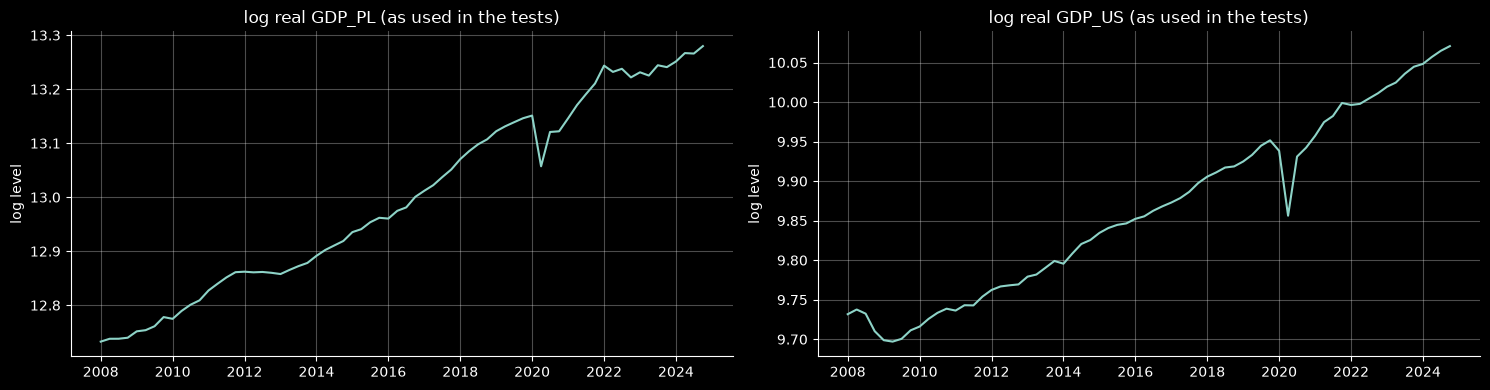

In [34]:
gdp = {k: raw[k] for k in ("GDP_PL", "GDP_US") if k in raw}

annual = pd.DataFrame({k: s.groupby(s.index.year).mean().pct_change() * 100 for k, s in gdp.items()}).loc[2009:2024]
annual.index.name = "year"
display(annual.style.format("{:.1f}").set_caption("Annual real GDP growth, %"))

rows = []
for k, s in gdp.items():
    q = s.copy(); q.index = q.index.to_period("Q")
    gaps = pd.period_range(q.index.min(), q.index.max(), freq="Q").difference(q.index)
    g = np.log(q).diff().dropna() * 100                     # q/q log growth, as used in the tests
    mad = 1.4826 * (g - g.median()).abs().median()
    flags = g[(g - g.median()).abs() > 4 * mad]
    rows.append({"series": k, "quarters": len(q), "missing quarters": len(gaps),
                 "median Δlog GDP ×100": g.median(), "flagged quarters": ", ".join(f"{p} ({v:+.1f}%)" for p, v in flags.items()) or "none"})
gdp_check = pd.DataFrame(rows).set_index("series")
display(gdp_check.style.format(precision=2))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, (k, s) in zip(axes, gdp.items()):
    ls = np.log(s.loc[START:END])
    ax.plot(ls.index, ls, lw=1.5)
    ax.set(title=f"log real {k} (as used in the tests)", ylabel="log level")
plt.tight_layout(); plt.show()

## 4. Build the analysis datasets

* **Monthly** (H1, H2): month-end index closes and FX; macro series aligned to the month; inflation in % y/y.
* **Quarterly** (GDP pairs): quarter-end index closes and real GDP.
* **Weekly** (H3): Friday closes. Daily closes on the Warsaw and New York exchanges are about 6 hours apart, and weekly data avoids this non-synchronous trading.

Indices, FX, GDP and EPU are in natural logs. Rates (inflation, unemployment, interest) are in percent.

In [35]:
def to_month_start(s):
    s = s.copy(); s.index = s.index.to_period("M").to_timestamp()
    return s.groupby(level=0).last()

daily = (pd.concat([raw["WIG20"], raw["SP500"], raw["USDPLN"]], axis=1, sort=True)
           .loc[START:END].asfreq("B").ffill(limit=3))
daily["SP500_PLN"] = daily["SP500"] * daily["USDPLN"]
daily["WIG20_USD"] = daily["WIG20"] / daily["USDPLN"]

# ---- Monthly ----
monthly = to_month_start(daily.resample(MONTH_END).last())
for c in ["INFL_PL", "INFL_US", "UNEMP_PL", "UNEMP_US", "RATE_PL", "RATE_US", "EPU_US", "EPU_PL"]:
    if c in raw:
        monthly[c] = to_month_start(raw[c])
monthly = monthly.loc[START:END]

m = monthly.copy()                                  # analysis version: logs where appropriate
for c in ["WIG20", "SP500", "USDPLN", "SP500_PLN", "WIG20_USD", "EPU_US", "EPU_PL"]:
    if c in m: m[c] = np.log(m[c])

# ---- Quarterly (for GDP) ----
q = daily[["WIG20", "SP500"]].resample(QUARTER_END).last()
q.index = q.index.to_period("Q").to_timestamp()
q = np.log(q)
for c in ["GDP_PL", "GDP_US"]:
    if c in raw:
        g = raw[c].copy(); g.index = g.index.to_period("Q").to_timestamp()
        q[c] = np.log(g.groupby(level=0).last())
q = q.loc[START:END]

# ---- Weekly (H3) ----
weekly = daily.resample("W-FRI").last().dropna().loc[START:END]
w_logs = np.log(weekly[["WIG20", "SP500_PLN", "USDPLN"]])
w_ret  = w_logs.diff().dropna() * 100

print(f"Monthly:   {len(m)} obs, columns: {list(m.columns)}")
print(f"Quarterly: {len(q)} obs, columns: {list(q.columns)}")
print(f"Weekly:    {len(weekly)} obs")
monthly.describe().T

Monthly:   204 obs, columns: ['WIG20', 'SP500', 'USDPLN', 'SP500_PLN', 'WIG20_USD', 'INFL_PL', 'INFL_US', 'UNEMP_PL', 'UNEMP_US', 'RATE_PL', 'RATE_US', 'EPU_US', 'EPU_PL']
Quarterly: 68 obs, columns: ['WIG20', 'SP500', 'GDP_PL', 'GDP_US']
Weekly:    887 obs


,count,mean,std,min,25%,50%,75%,max
WIG20,204.0000,2219.7463,324.4339,1372.4700,1994.2625,2277.0000,2417.2525,2981.0700
SP500,204.0000,2541.9966,1311.4614,735.0900,1384.0225,2116.7699,3397.3275,6032.3799
USDPLN,204.0000,3.5591,0.5459,2.0509,3.1459,3.7114,3.9588,4.9533
SP500_PLN,204.0000,9564.1074,5878.4166,2599.2697,4401.7957,8372.6498,12952.8783,24594.0128
WIG20_USD,204.0000,651.0572,197.5340,278.1802,529.2684,614.9759,753.2324,1342.0888
INFL_PL,204.0000,3.6250,4.0939,-1.6000,1.3000,2.8500,4.3000,18.4000
INFL_US,199.0000,2.5305,2.0664,-2.1000,1.4000,2.1000,3.2000,9.1000
UNEMP_PL,201.0000,8.8035,3.1674,4.8000,5.6000,8.8000,11.8000,14.4000
UNEMP_US,201.0000,6.0095,2.2766,3.4000,4.0000,5.3000,7.8000,14.7000
RATE_PL,204.0000,3.1162,1.9733,0.1000,1.5000,2.5000,4.5000,6.7500


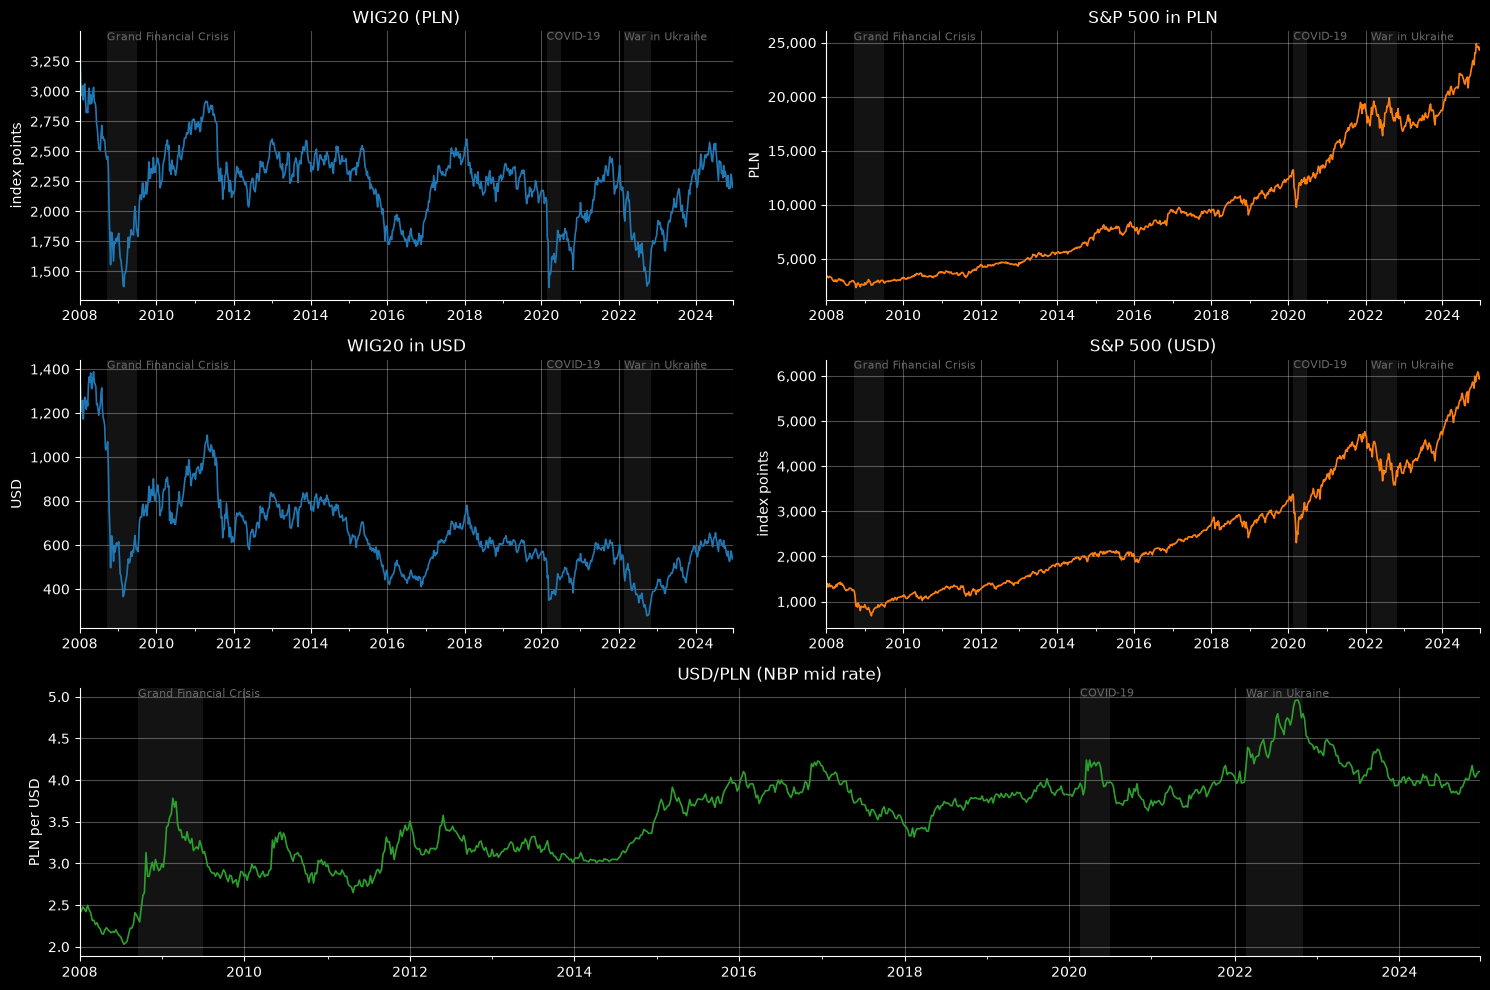

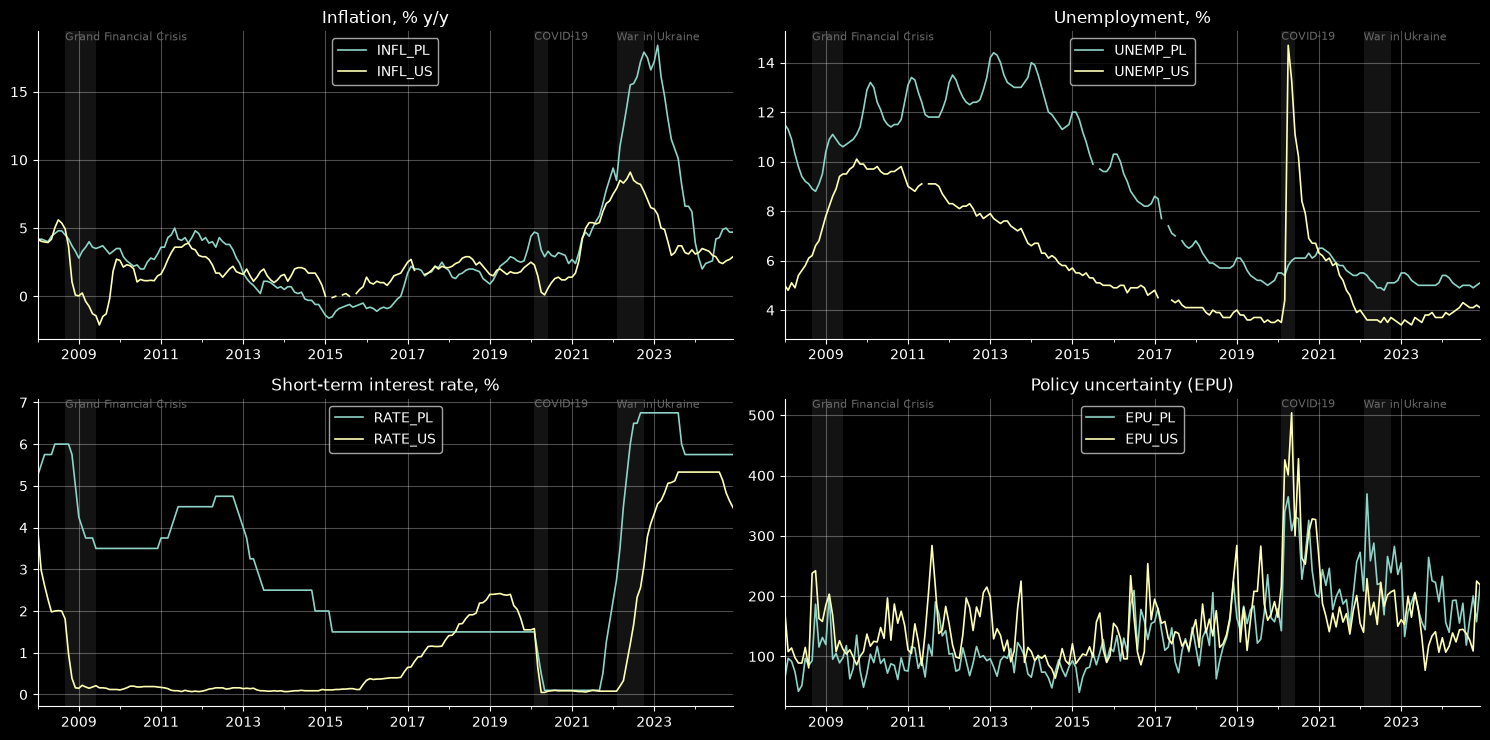

In [36]:
from matplotlib.ticker import StrMethodFormatter

# Each index on its own axis in its real units: columns = index, rows = currency
market_panels = [("WIG20",     "WIG20 (PLN)",    "index points", "tab:blue"),
                 ("SP500_PLN", "S&P 500 in PLN", "PLN",          "tab:orange"),
                 ("WIG20_USD", "WIG20 in USD",   "USD",          "tab:blue"),
                 ("SP500",     "S&P 500 (USD)",  "index points", "tab:orange")]
fig = plt.figure(figsize=(15, 10))
grid = fig.add_gridspec(3, 2)
for k, (col, title, unit, color) in enumerate(market_panels):
    ax = fig.add_subplot(grid[k // 2, k % 2])
    weekly[col].plot(ax=ax, lw=1.2, color=color, title=title)
    ax.set(xlabel="", ylabel=unit); ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}")); shade_events(ax)
ax = fig.add_subplot(grid[2, :])
weekly["USDPLN"].plot(ax=ax, lw=1.2, color="tab:green", title="USD/PLN (NBP mid rate)")
ax.set(xlabel="", ylabel="PLN per USD"); shade_events(ax)
plt.tight_layout(); plt.savefig(FIG_DIR / "01_markets.png", dpi=150); plt.show()

macro_panels = [("Inflation, % y/y", ["INFL_PL", "INFL_US"]), ("Unemployment, %", ["UNEMP_PL", "UNEMP_US"]),
                ("Short-term interest rate, %", ["RATE_PL", "RATE_US"]), ("Policy uncertainty (EPU)", ["EPU_PL", "EPU_US"])]
fig, axes = plt.subplots(2, 2, figsize=(15, 7.5))
for ax, (title, cols) in zip(axes.flat, macro_panels):
    cols = [c for c in cols if c in monthly]
    if cols: monthly[cols].plot(ax=ax, lw=1.2, title=title)
    else: ax.set_title(title + " (not available)")
    ax.set_xlabel(""); shade_events(ax)
plt.tight_layout(); plt.savefig(FIG_DIR / "02_macro.png", dpi=150); plt.show()

## 5. Unit-root and stationarity tests

Cointegration requires every series to be integrated of order 1, $I(1)$: non-stationary in levels and stationary in first differences. Three tests with different null hypotheses are combined:

* **Augmented Dickey-Fuller (ADF, 1979):** $H_0$: unit root. The test regression is

  $$\Delta y_t = c + \delta t + \rho\,y_{t-1} + \sum_{i=1}^{k}\phi_i\,\Delta y_{t-i} + \varepsilon_t, \qquad H_0: \rho = 0, \quad H_1: \rho < 0$$

  where the lagged differences remove autocorrelation from $\varepsilon_t$ and the lag length $k$ is selected by the Akaike Information Criterion (AIC; Akaike, 1974).
* **Kwiatkowski-Phillips-Schmidt-Shin (KPSS, 1992):** $H_0$: stationarity around a deterministic mean or trend. The series is split into a trend, a random walk and a stationary error,

  $$y_t = \xi t + r_t + \varepsilon_t, \qquad r_t = r_{t-1} + u_t, \qquad H_0: \sigma_u^2 = 0$$

  so under $H_0$ the random-walk component is constant and $y_t$ is (trend-)stationary.
* **Zivot-Andrews (1992):** $H_0$: unit root without a structural break; $H_1$: stationarity with one break at an unknown date (for example the 2008 financial crisis, the 2020 COVID-19 shock or the 2022 war in Ukraine). The ADF regression is extended with break dummies,

  $$\Delta y_t = c + \theta\,DU_t(\tau) + \delta t + \gamma\,DT_t(\tau) + \rho\,y_{t-1} + \sum_{i=1}^{k}\phi_i\,\Delta y_{t-i} + \varepsilon_t$$

  where $DU_t(\tau) = 1$ and $DT_t(\tau) = t - \tau$ for $t > \tau$ (0 otherwise) shift the level and the trend after the break. The break date $\tau$ is the one that gives the most negative t-statistic on $\rho$. Standard ADF tests lose power when a sample starts during a market crash, and Zivot-Andrews protects against classifying a series with a broken trend as a unit root.

In the deterministic part, $c$ is always included and the trend $\delta t$ only for trending series (see the rules below).

### Classification rules

* A series counts as stationary in levels, $I(0)$, only if all three tests agree: ADF and Zivot-Andrews reject the unit root, and KPSS does not reject stationarity.
* A first-differenced series counts as stationary if ADF rejects the unit root or KPSS does not reject stationarity.
* When the evidence is mixed, the series is treated as $I(1)$, the standard assumption for asset prices under weak-form market efficiency (*Fama, 1970*).
* Trending series (stock indices and GDP) are tested with a constant and a time trend ($c, t$); all other series (rates, EPU and USD/PLN) with a constant only ($c$).
* `statsmodels` interpolates KPSS p-values from a table that covers only 0.01–0.10. A reported **0.1000 means $p \geq 0.10$** and **0.0100 means $p \leq 0.01$**. The 5% threshold lies inside this range, so the classifications are unaffected.

In [37]:
TRENDING = {"WIG20", "SP500", "SP500_PLN", "WIG20_USD", "GDP_PL", "GDP_US"}

def unit_root_table(df, freq_label):
    rows = []
    for col in df.columns:
        x = df[col].dropna()
        if len(x) < 30: continue
        trend = "ct" if col in TRENDING else "c"
        a_l = adfuller(x, regression=trend, autolag="AIC")[1]
        k_l = kpss(x, regression=trend, nlags="auto")[1]
        z_l = zivot_andrews(x, regression=trend, autolag="AIC")[1]
        a_d = adfuller(x.diff().dropna(), regression="c", autolag="AIC")[1]
        k_d = kpss(x.diff().dropna(), regression="c", nlags="auto")[1]
        level_stationary = a_l < SIGNIF and z_l < SIGNIF and k_l > SIGNIF
        diff_stationary = a_d < SIGNIF or k_d > SIGNIF
        order = "I(0)" if level_stationary else ("I(1)" if diff_stationary else "I(2)?")
        rows.append({"freq": freq_label, "series": col, "n": len(x),
                     "ADF p (level)": a_l, "ZA p (level)": z_l, "KPSS p (level)": k_l,
                     "ADF p (diff)": a_d, "KPSS p (diff)": k_d, "order": order})
    return pd.DataFrame(rows)

ur = pd.concat([
    unit_root_table(m.drop(columns=["WIG20_USD", "SP500_PLN"]), "monthly"),
    unit_root_table(q[[c for c in q if c.startswith("GDP")]], "quarterly"),
    unit_root_table(w_logs, "weekly"),
]).set_index(["freq", "series"])
display(ur)

def is_I1(freq, col):
    if freq == "quarterly" and col in ("WIG20", "SP500"):
        freq = "monthly"                       # index order doesn't depend on sampling frequency
    try: return ur.loc[(freq, col), "order"] == "I(1)"
    except KeyError: return False

n  ADF p (level)  ZA p (level)  KPSS p (level)  \
freq      series                                                        
monthly   WIG20      204         0.0739        0.6502          0.1000   
          SP500      204         0.0024        0.0983          0.1000   
          USDPLN     204         0.1550        0.4154          0.0100   
          INFL_PL    204         0.6158        0.4232          0.0219   
          INFL_US    199         0.1277        0.0467          0.0260   
          UNEMP_PL   201         0.7289        0.2530          0.0100   
          UNEMP_US   201         0.1315        0.0600          0.0100   
          RATE_PL    204         0.2058        0.0000          0.0896   
          RATE_US    204         0.2232        0.0019          0.0100   
          EPU_US     204         0.0076        0.1412          0.0240   
          EPU_PL     204         0.1902        0.0081          0.0100   
quarterly GDP_PL      68         0.0527        0.2659          0.1000   
          GDP_US      68         0.0020        0.0114          0.0467   
weekly    WIG20      887         0.0156        0.2406          0.1000   
          SP500_PLN  887         0.0000        0.0018          0.0118   
          USDPLN     887         0.1690        0.3112          0.0100   

                     ADF p (diff)  KPSS p (diff) order  
freq      series                                        
monthly   WIG20            0.0000         0.1000  I(1)  
          SP500            0.0000         0.1000  I(1)  
          USDPLN           0.0000         0.1000  I(1)  
          INFL_PL          0.0000         0.1000  I(1)  
          INFL_US          0.0001         0.1000  I(1)  
          UNEMP_PL         0.0776         0.1000  I(1)  
          UNEMP_US         0.0000         0.1000  I(1)  
          RATE_PL          0.0014         0.1000  I(1)  
          RATE_US          0.0097         0.0677  I(1)  
          EPU_US           0.0000         0.0779  I(1)  
          EPU_PL           0.0000         0.1000  I(1)  
quarterly GDP_PL           0.0000         0.1000  I(1)  
          GDP_US           0.0000         0.1000  I(1)  
weekly    WIG20            0.0000         0.1000  I(1)  
          SP500_PLN        0.0000         0.1000  I(1)  
          USDPLN           0.0000         0.1000  I(1)

> **Inflation and EPU** are often found stationary, I(0). A stationary variable cannot offset a stochastic trend, so in that case it cannot be cointegrated with an I(1) index. The tables below therefore show the I(1) check for every pair.

## 6. Spurious regression in levels

This section shows what a naive OLS regression of each index on each macro variable, in levels, would conclude. Every pair tested later is included.

With trending, non-stationary series, the usual t-statistics and p-values are invalid. The residuals are non-stationary, so the standard errors are far too small, and unrelated series often produce a high $R^2$ and "significant" coefficients.

Granger & Newbold (1974) give a simple warning sign of a spurious regression:
$$R^2 > DW$$
where $DW$ is the Durbin-Watson (1950) statistic. A high $R^2$ together with a very low Durbin-Watson statistic indicates strong residual autocorrelation, so the apparent relationship is likely spurious.

In [38]:
from statsmodels.stats.stattools import durbin_watson

HYP = {"INFL": "H1", "UNEMP": "H1", "RATE": "H1", "GDP": "H1", "EPU": "H2", "USDPLN": "H3", "SP500": "H3"}
DATA = {"monthly": m, "quarterly": q}

PAIRS = []                                          # (index, variable, frequency)
for idx, cc in [("WIG20", "PL"), ("SP500", "US")]:
    for v in ["INFL", "UNEMP", "RATE", "EPU"]:
        if f"{v}_{cc}" in m: PAIRS.append((idx, f"{v}_{cc}", "monthly"))
    if f"GDP_{cc}" in q: PAIRS.append((idx, f"GDP_{cc}", "quarterly"))
PAIRS += [("WIG20", "USDPLN", "monthly"), ("WIG20", "SP500", "monthly")]

def pair_key(y, x): return (HYP[x.split("_")[0]], y, x)

def pair_data(y, x, freq):
    return DATA[freq][[y, x]].dropna()

rows = []
for y, x, freq in PAIRS:
    d = pair_data(y, x, freq)
    ols = sm.OLS(d[y], sm.add_constant(d[x])).fit()
    dw = durbin_watson(ols.resid)
    rows.append(dict(zip(["hypothesis", "index", "variable"], pair_key(y, x)),
                     freq=freq, n=len(d), **{"slope b": ols.params[x], "t-stat (naive)": ols.tvalues[x],
                     "R²": ols.rsquared, "Durbin-Watson": dw, "R² > DW (spurious warning)": ols.rsquared > dw}))
naive = pd.DataFrame(rows).set_index(["hypothesis", "index", "variable"]).sort_index()
display(naive.style.format(precision=3))
n_sig = int((naive["t-stat (naive)"].abs() > T_CRIT).sum())
print(f"A naive levels regression calls {n_sig} of {len(naive)} relationships 'significant' (|t| > {T_CRIT:.2f}). "
      f"Durbin-Watson is below 0.5 in {int((naive['Durbin-Watson'] < 0.5).sum())} of them.")

A naive levels regression calls 11 of 12 relationships 'significant' (|t| > 1.96). Durbin-Watson is below 0.5 in 10 of them.


# Part A: Engle-Granger cointegration (no structural break)

Part A assumes that each long-run relationship stays the same over the whole 2008–2024 sample. It is the classical baseline: the two-step Engle-Granger (1987) procedure with MacKinnon (2010) critical values. Part B drops this assumption and allows one structural break in the cointegrating vector.

## 7. Engle-Granger cointegration (H1, H2 and H3 pairs)

Each pair of a stock index and an explanatory variable goes through the two-step Engle-Granger (1987) procedure:

1. Estimate the long-run regression
   $$\text{index}_t = a + b \cdot x_t + u_t$$
   which gives the cointegrating vector $[1, -b]$.
2. Test the residuals $\hat{u}_t$ for stationarity with `statsmodels.tsa.stattools.coint`, which uses MacKinnon (2010) critical values (about $-3.37$ at 5%). Standard Dickey-Fuller (1979) critical values ($-2.86$) do not apply, because the residuals come from an estimated regression.
3. Classify the pair as cointegrated if and only if both series are $I(1)$ and the Engle-Granger p-value is below 0.05.

### Interpreting the coefficient

* **Log-log pairs:** indices, FX rates, GDP and EPU are in natural logs ($\ln$), so $b$ is an elasticity: the % change in the index for a 1% change in the variable.
* **Semi-log pairs:** rates (inflation, unemployment and interest rates) enter in levels against the log index, so $b$ is the % change in the index for a 1 percentage point change in the rate.

In [39]:
rows = []
for y, x, freq in PAIRS:
    d = pair_data(y, x, freq)
    stat, p, crit = coint(d[y], d[x], trend="c", autolag="aic")
    pre = is_I1(freq, y) and is_I1(freq, x)
    rows.append(dict(zip(["hypothesis", "index", "variable"], pair_key(y, x)), freq=freq, n=len(d),
                     **{"b (long-run)": naive.loc[pair_key(y, x), "slope b"], "EG stat": stat, f"{SIG_LABEL} crit": crit[CRIT_COL],
                        "EG p": p, "both I(1)": pre, "EG cointegrated": bool(pre and p < SIGNIF)}))
eg_tbl = pd.DataFrame(rows).set_index(["hypothesis", "index", "variable"]).sort_index()
display(eg_tbl.style.format(precision=3))

## 8. Error-correction models (Engle-Granger pairs)

For each pair that Engle-Granger (1987) finds cointegrated, an error-correction model (ECM) is estimated with the lagged residual $\hat{u}_{t-1}$ from the long-run regression:

$$\Delta y_t = c + \gamma \, \hat{u}_{t-1} + \phi \, \Delta y_{t-1} + \theta_0 \, \Delta x_t + \theta_1 \, \Delta x_{t-1} + \varepsilon_t$$

* $\gamma$ is the share of last period's deviation from equilibrium that is corrected in the current period. The model describes a return to equilibrium only if $\gamma$ is negative and significant.
* The half-life is the number of periods needed to close half of a deviation:
  $$\text{Half-life} = \frac{\ln(0.5)}{\ln(1 + \gamma)}$$
* Standard errors and t-statistics use the Newey-West (1987) HAC estimator, which allows for heteroskedasticity and autocorrelation in the short-run dynamics.

In [40]:
def ecm(d, y, x, model=None, tb=None):
    if model is None:                                   # Engle-Granger long-run regression
        X = sm.add_constant(d[x]).values
    else:                                               # Gregory-Hansen regression with its break (Part B)
        X = gh_design(d[x].values, len(d), tb, model)
    coef = np.linalg.lstsq(X, d[y].values, rcond=None)[0]
    u = pd.Series(d[y].values - X @ coef, index=d.index)
    data = pd.DataFrame({"dy": d[y].diff(), "ect": u.shift(1), "dy_l1": d[y].diff().shift(1),
                         "dx": d[x].diff(), "dx_l1": d[x].diff().shift(1)}).dropna()
    fit = sm.OLS(data["dy"], sm.add_constant(data.drop(columns="dy"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
    g = fit.params["ect"]
    return {"gamma": g, "p-value": fit.pvalues["ect"], f"significant at {SIG_LABEL}": fit.pvalues["ect"] < SIGNIF,
            "half-life (periods)": np.log(0.5) / np.log(1 + g) if -1 < g < 0 else np.nan, "R²": fit.rsquared}

freq_of = {pair_key(a, b): f for a, b, f in PAIRS}

def ecm_table(rows):
    tbl = pd.DataFrame(rows).T
    if not tbl.empty:
        tbl.index.names = ["hypothesis", "index", "variable"]
        tbl["unit"] = ["quarters" if freq_of[k] == "quarterly" else "months" for k in tbl.index]
    return tbl

ecm_eg_rows = {}
for y, x, freq in PAIRS:
    k = pair_key(y, x)
    if eg_tbl.loc[k, "EG cointegrated"]:
        ecm_eg_rows[k] = {"based on": "Engle-Granger", **ecm(pair_data(y, x, freq), y, x)}
ecm_eg = ecm_table(ecm_eg_rows)
if ecm_eg.empty:
    print("No pair is cointegrated under Engle-Granger, so no ECM is estimated.")
else:
    display(ecm_eg)

based on   gamma p-value significant at 5%  \
hypothesis index variable                                                    
H1         WIG20 INFL_PL   Engle-Granger -0.1086  0.0008              True   
                 UNEMP_PL  Engle-Granger -0.1224  0.0001              True   
H2         WIG20 EPU_PL    Engle-Granger -0.1322  0.0002              True   
H1         WIG20 GDP_PL    Engle-Granger -0.4440  0.0000              True   
H3         WIG20 USDPLN    Engle-Granger -0.0958  0.0000              True   
                 SP500     Engle-Granger -0.0690  0.0010              True   

                          half-life (periods)     R²      unit  
hypothesis index variable                                       
H1         WIG20 INFL_PL               6.0277 0.1130    months  
                 UNEMP_PL              5.3067 0.0817    months  
H2         WIG20 EPU_PL                4.8900 0.1176    months  
H1         WIG20 GDP_PL                1.1808 0.3031  quarters  
H3         WIG20 USDPLN                6.8855 0.4517    months  
                 SP500                 9.6982 0.5337    months

## 9. H3 (weekly): Engle-Granger and stability over time

H3, the link between an emerging and a developed equity market (*Aggarwal, Inclan & Leal, 1999*; *Sarwar & Khan, 2017*), is tested on weekly data: WIG20 against the S&P 500 in PLN ($\text{S\&P 500} \times \text{USD/PLN}$).

* Weekly data gives about 880 observations for 2008–2024, much more than the monthly series, so the tests have more power.
* Daily closes are not used, because the Warsaw and New York sessions close about 6 hours apart.
* In PLN, the S&P 500 shows its value to a Polish investor, so both indices are in the same currency.

To check whether the relation is stable, the full-sample Engle-Granger (1987) test is repeated in rolling 3-year windows. If the link is persistent, the p-value should stay below 5% in most windows.

Engle-Granger WIG20 ~ SP500_PLN (weekly): p = 0.012


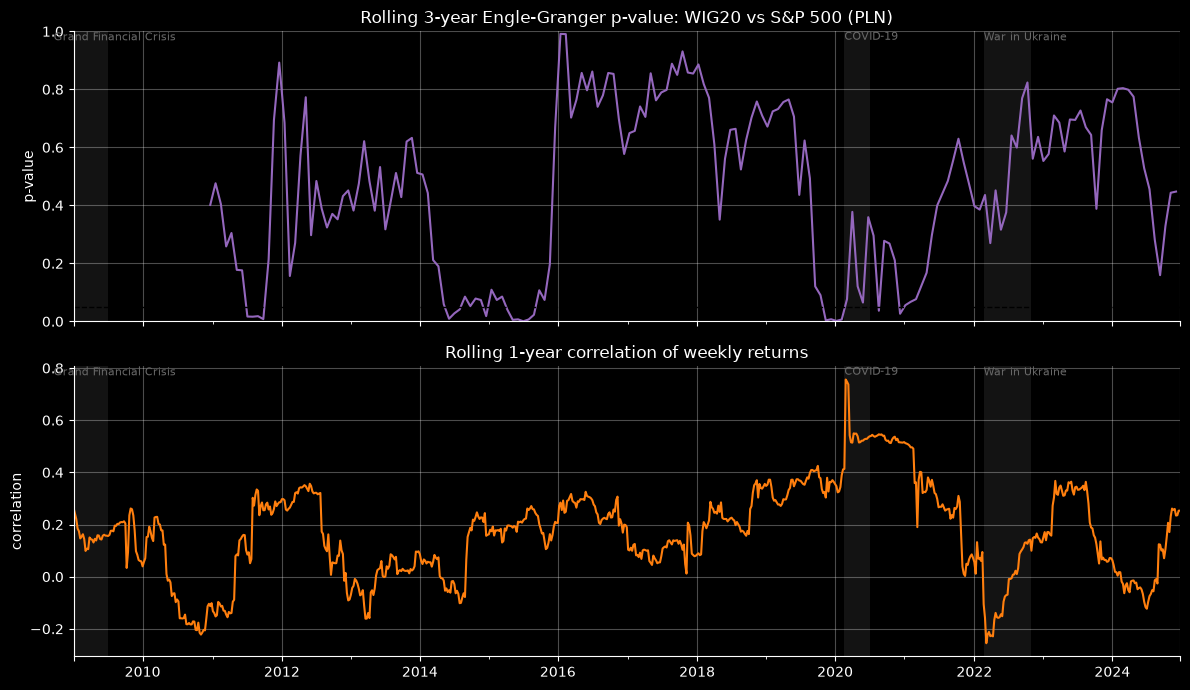

Share of 3-year windows with cointegration at 5%: 11%


In [41]:
eg_w = coint(w_logs["WIG20"], w_logs["SP500_PLN"], autolag="aic")[1]
print(f"Engle-Granger WIG20 ~ SP500_PLN (weekly): p = {eg_w:.3f}")

WIN_EG, WIN_CORR, STEP = 156, 52, 4      # 3-year EG window, 1-year correlation window (weeks)
eg_roll = pd.Series({w_logs.index[i - 1]: coint(w_logs["WIG20"].iloc[i - WIN_EG:i],
                                               w_logs["SP500_PLN"].iloc[i - WIN_EG:i], autolag="aic")[1]
                     for i in range(WIN_EG, len(w_logs) + 1, STEP)})
corr_roll = w_ret["WIG20"].rolling(WIN_CORR).corr(w_ret["SP500_PLN"]).dropna()

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
eg_roll.plot(ax=axes[0], color="tab:purple")
axes[0].axhline(SIGNIF, ls="--", color="black", lw=1)
axes[0].set(title="Rolling 3-year Engle-Granger p-value: WIG20 vs S&P 500 (PLN)", ylabel="p-value", ylim=(0, 1))
corr_roll.plot(ax=axes[1], color="tab:orange")
axes[1].set(title="Rolling 1-year correlation of weekly returns", ylabel="correlation", xlabel="")
for ax in axes: shade_events(ax)
plt.tight_layout(); plt.savefig(FIG_DIR / "03_h3_stability.png", dpi=150); plt.show()
print(f"Share of 3-year windows with cointegration at {SIG_LABEL}: {(eg_roll < SIGNIF).mean():.0%}")

# Part B: Gregory-Hansen cointegration (one structural break)

Part B repeats the tests from Part A but lets each long-run relationship shift once, at a break date estimated from the data. Shocks during 2008–2024, such as the financial crisis, the COVID-19 pandemic and the war in Ukraine, can hide a long-run relationship from the standard Engle-Granger (1987) test.

## 10. Gregory-Hansen cointegration (one structural break)

The Engle-Granger (1987) test assumes that each long-run relationship is fixed over the whole 17-year sample (2008–2024). Large shocks, such as the 2008 financial crisis, the 2020 COVID-19 pandemic and the 2022 war in Ukraine, may shift the cointegrating vector.

The Gregory-Hansen (1996) test allows one break at a date estimated from the data:
1. The long-run regression is estimated for every candidate break date $\tau$ in the middle 70% of the sample, $\tau \in [0.15T, 0.85T]$.
2. An ADF test is run on the residuals for each candidate date.
3. The smallest (most negative) statistic, $ADF^* = \inf_{\tau} ADF(\tau)$, is the test statistic, and its date is the estimated break.

### Models

The dummy $D_{t\tau}$ equals 1 if $t \geq \tau$ and 0 otherwise.

| Model | Long-run equation | What shifts |
| :--- | :--- | :--- |
| **C** (level shift) | $y_t = \mu_1 + \mu_2 D_{t\tau} + \beta x_t + u_t$ | Intercept |
| **C/T** (level shift with trend) | $y_t = \mu_1 + \mu_2 D_{t\tau} + \alpha t + \beta x_t + u_t$ | Intercept, with a time trend |
| **C/S** (regime shift) | $y_t = \mu_1 + \mu_2 D_{t\tau} + \beta_1 x_t + \beta_2 x_t D_{t\tau} + u_t$ | Intercept and slope (elasticity) |

### Critical values

Critical values for one regressor come from Gregory & Hansen (1996, Table 1). At 5% they are about $-4.61$ (C), $-4.99$ (C/T) and $-4.95$ (C/S), well below the Engle-Granger value of about $-3.37$, because the search over break dates would otherwise inflate the type I error rate.

In [42]:
# Gregory & Hansen (1996), Table 1, one regressor (m = 1): critical values at 1%, 5%, 10%
GH_CRIT = {"C": (-5.13, -4.61, -4.34), "C/T": (-5.45, -4.99, -4.72), "C/S": (-5.47, -4.95, -4.68)}

def gh_design(x, n, tb, model):
    D = (np.arange(n) >= tb).astype(float)
    cols = [np.ones(n), D]
    if model == "C/T": cols.append(np.arange(n, dtype=float))
    cols.append(x)
    if model == "C/S": cols.append(x * D)
    return np.column_stack(cols)

def gregory_hansen(y, x, model="C", trim=0.15, step=1):
    # Returns (ADF* statistic, break position, OLS coefficients at the break)
    y, x = np.asarray(y, float), np.asarray(x, float)
    n = len(y)
    best = (np.inf, None, None)
    for tb in range(int(trim * n), int((1 - trim) * n), step):
        X = gh_design(x, n, tb, model)
        coef = np.linalg.lstsq(X, y, rcond=None)[0]
        stat = adfuller(y - X @ coef, regression="n", autolag="AIC")[0]
        if stat < best[0]:
            best = (stat, tb, coef)
    return best

def gh_pair(d, y, x, step=1):
    out = {}
    for model in GH_CRIT:
        stat, tb, coef = gregory_hansen(d[y], d[x], model, step=step)
        out[model] = {"ADF*": stat, "crit": GH_CRIT[model][CRIT_COL], "significant": stat < GH_CRIT[model][CRIT_COL],
                      "break": d.index[tb], "coef": coef}
    return out

gh_raw, rows = {}, []
for y, x, freq in PAIRS:
    d = pair_data(y, x, freq)
    res = gh_raw[pair_key(y, x)] = gh_pair(d, y, x)
    # best model = the one furthest below its own critical value (at SIGNIF)
    best = min(res, key=lambda k: res[k]["ADF*"] - res[k]["crit"])
    pre = is_I1(freq, y) and is_I1(freq, x)
    row = dict(zip(["hypothesis", "index", "variable"], pair_key(y, x)), freq=freq)
    for model, r in res.items():
        row[f"{model} ADF*"] = r["ADF*"]
        row[f"{model} sig."] = r["significant"]
    row.update({"best model": best, "break date": res[best]["break"].strftime("%Y-%m"),
                "GH cointegrated": bool(pre and res[best]["significant"])})
    if best == "C/S":   # slope before and after the break
        c = res[best]["coef"]; row["slope before → after"] = f"{c[2]:.3f} → {c[2] + c[3]:.3f}"
    rows.append(row)
gh_tbl = pd.DataFrame(rows).set_index(["hypothesis", "index", "variable"]).sort_index()
display(gh_tbl.style.format(precision=3))

## 11. Error-correction models (pairs cointegrated only with a break)

Pairs already cointegrated under Engle-Granger (1987) keep their ECM from Part A.

For pairs that are cointegrated only once a break is allowed, the ECM uses the residual $\hat{u}_{t-1}$ from the best-fitting Gregory-Hansen (1996) model (C, C/T or C/S) at the estimated break date $\hat{\tau}$:

$$\Delta y_t = c + \gamma \, \hat{u}_{t-1, \text{GH}} + \phi \, \Delta y_{t-1} + \theta_0 \, \Delta x_t + \theta_1 \, \Delta x_{t-1} + \varepsilon_t$$

$\gamma$ then measures the adjustment toward the break-adjusted equilibrium.

In [43]:
ecm_gh_rows = {}
for y, x, freq in PAIRS:
    k = pair_key(y, x)
    if not eg_tbl.loc[k, "EG cointegrated"] and gh_tbl.loc[k, "GH cointegrated"]:
        d = pair_data(y, x, freq)
        model = gh_tbl.loc[k, "best model"]; tb = d.index.get_loc(gh_raw[k][model]["break"])
        ecm_gh_rows[k] = {"based on": f"Gregory-Hansen {model}", **ecm(d, y, x, model, tb)}
ecm_gh = ecm_table(ecm_gh_rows)
if ecm_gh.empty:
    print("No pair is cointegrated only under Gregory-Hansen.")
else:
    display(ecm_gh)

# All ECMs (Part A + Part B), in the order of PAIRS
ecm_tbl = ecm_table({pair_key(y, x): {**ecm_eg_rows, **ecm_gh_rows}[pair_key(y, x)] for y, x, _ in PAIRS
                     if pair_key(y, x) in ecm_eg_rows or pair_key(y, x) in ecm_gh_rows})

,,,based on,gamma,p-value,significant at 5%,half-life (periods),R²,unit
hypothesis,index,variable,,,,,,,
H1,WIG20,RATE_PL,Gregory-Hansen C,-0.1082,0.0008,True,6.0555,0.0692,months
H2,SP500,EPU_US,Gregory-Hansen C/T,-0.1494,0.0004,True,4.2838,0.1354,months
H1,SP500,GDP_US,Gregory-Hansen C/S,-0.3910,0.0281,True,1.3977,0.1370,quarters


## 12. H3 (weekly): Gregory-Hansen and the estimated break

The weekly Engle-Granger (1987) test from Section 9 is repeated with the Gregory-Hansen (1996) test, for WIG20 and the S&P 500 in PLN ($\text{S\&P 500} \times \text{USD/PLN}$).

The test checks whether the long-run link between the two markets shifted once over the ~880 weekly observations (2008–2024). The break week $\hat{\tau}$ is the one with the smallest $ADF^*$ across models C, C/T and C/S; to save time, every second week is a candidate. The question is whether the full-sample link survives once a major dislocation is allowed for, such as the Lehman Brothers collapse in 2008, the COVID-19 shock in March 2020 or the start of the war in Ukraine in February 2022.

Gregory-Hansen WIG20 ~ SP500_PLN (weekly): C: ADF* = -4.55 (5% crit -4.61), break 2010-08; C/T: ADF* = -4.00 (5% crit -4.99), break 2015-06; C/S: ADF* = -4.78 (5% crit -4.95), break 2020-08


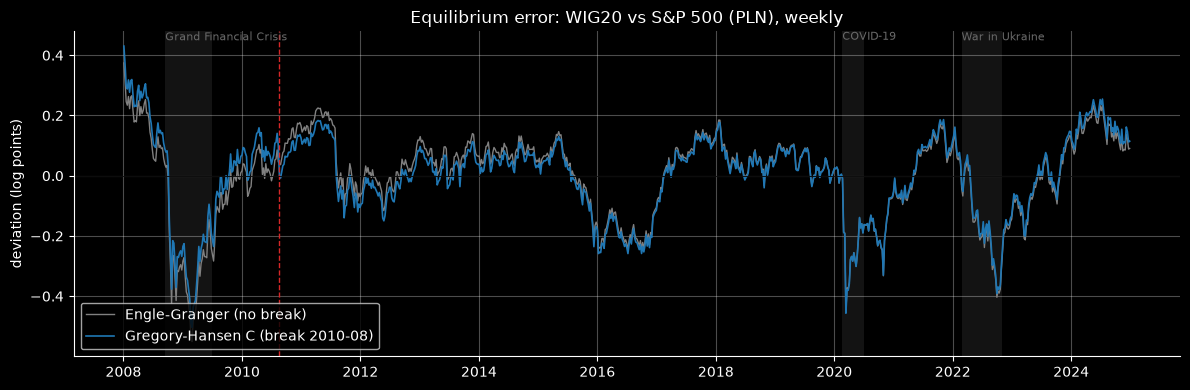

In [44]:
gh_w = gh_pair(w_logs, "WIG20", "SP500_PLN", step=2)          # every 2nd week as candidate break, for speed
gh_w_best = min(gh_w, key=lambda k: gh_w[k]["ADF*"] - gh_w[k]["crit"])
print("Gregory-Hansen WIG20 ~ SP500_PLN (weekly): " + "; ".join(
    f"{k}: ADF* = {v['ADF*']:.2f} ({SIG_LABEL} crit {v['crit']}), break {v['break']:%Y-%m}" for k, v in gh_w.items()))

# Equilibrium error with and without the Gregory-Hansen break
y_, x_ = w_logs["WIG20"].values, w_logs["SP500_PLN"].values
X_eg = sm.add_constant(x_)
u_eg = y_ - X_eg @ np.linalg.lstsq(X_eg, y_, rcond=None)[0]
tb_w = w_logs.index.get_loc(gh_w[gh_w_best]["break"])
X_gh = gh_design(x_, len(y_), tb_w, gh_w_best)
u_gh = y_ - X_gh @ np.linalg.lstsq(X_gh, y_, rcond=None)[0]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(w_logs.index, u_eg, lw=1, color="grey", label="Engle-Granger (no break)")
ax.plot(w_logs.index, u_gh, lw=1.2, color="tab:blue", label=f"Gregory-Hansen {gh_w_best} (break {gh_w[gh_w_best]['break']:%Y-%m})")
ax.axvline(gh_w[gh_w_best]["break"], ls="--", color="tab:red", lw=1)
ax.axhline(0, color="black", lw=0.6)
ax.set(title="Equilibrium error: WIG20 vs S&P 500 (PLN), weekly", ylabel="deviation (log points)")
ax.legend(loc="lower left"); shade_events(ax)
plt.tight_layout(); plt.savefig(FIG_DIR / "04_h3_break.png", dpi=150); plt.show()

# Part C: comparison of the results with and without a break

## 13. Engle-Granger vs. Gregory-Hansen

Each relationship is placed in one of four groups at the 5% level (both series must be $I(1)$):

| Group | Meaning |
| :--- | :--- |
| **Cointegrated in both** | The strongest evidence: a long-run relationship that holds whether or not a break is modelled. |
| **Cointegrated only with a break** | Missed by Engle-Granger (1987) because the relationship shifted once; it holds within each regime. |
| **Engle-Granger only** | Found by Engle-Granger but not significant under the stricter Gregory-Hansen (1996) critical values, so it is not robust to a break and should be read with caution. |
| **Not cointegrated** | No long-run relationship with or without a break. |

In [45]:
def change(eg, gh):
    if eg and gh: return "cointegrated in both"
    if gh:        return "only with a break"
    if eg:        return "Engle-Granger only"
    return "not cointegrated"

compare = pd.DataFrame({
    "freq": eg_tbl["freq"],
    "EG p": eg_tbl["EG p"],
    "EG cointegrated": eg_tbl["EG cointegrated"],
    "GH best model": gh_tbl["best model"],
    "GH ADF*": [gh_raw[k][gh_tbl.loc[k, "best model"]]["ADF*"] for k in gh_tbl.index],
    f"GH {SIG_LABEL} crit": [GH_CRIT[gh_tbl.loc[k, "best model"]][CRIT_COL] for k in gh_tbl.index],
    "GH break": gh_tbl["break date"],
    "GH cointegrated": gh_tbl["GH cointegrated"],
})
compare["result"] = [change(e, g) for e, g in zip(compare["EG cointegrated"], compare["GH cointegrated"])]

# H3 weekly test (WIG20 ~ SP500_PLN) as an extra row
w_I1 = is_I1("weekly", "WIG20") and is_I1("weekly", "SP500_PLN")
w_eg, w_gh = bool(w_I1 and eg_w < SIGNIF), bool(w_I1 and gh_w[gh_w_best]["significant"])
weekly_row = pd.DataFrame([{
    "freq": "weekly", "EG p": eg_w, "EG cointegrated": w_eg, "GH best model": gh_w_best,
    "GH ADF*": gh_w[gh_w_best]["ADF*"], f"GH {SIG_LABEL} crit": gh_w[gh_w_best]["crit"],
    "GH break": f"{gh_w[gh_w_best]['break']:%Y-%m}", "GH cointegrated": w_gh, "result": change(w_eg, w_gh)}],
    index=pd.MultiIndex.from_tuples([("H3", "WIG20", "SP500_PLN (weekly)")], names=compare.index.names))
compare = pd.concat([compare, weekly_row])
display(compare.style.format(precision=3))

# Count per hypothesis and index: Engle-Granger alone vs. allowing a break
lines = ["| Hypothesis | Index | Engle-Granger only | Allowing a break (EG or GH) | What changes |",
         "|---|---|---|---|---|"]
for (h, idx), sub in compare.groupby(level=["hypothesis", "index"], sort=True):
    n, n_eg, n_any = len(sub), int(sub["EG cointegrated"].sum()), int((sub["EG cointegrated"] | sub["GH cointegrated"]).sum())
    notes = [f"{v}: {r}" + (f" ({b})" if r == "only with a break" else "")
             for (_, _, v), r, b in zip(sub.index, sub["result"], sub["GH break"])
             if r in ("only with a break", "Engle-Granger only")]
    lines.append(f"| {h} | {idx} | {n_eg}/{n} | {n_any}/{n} | {'; '.join(notes) or 'no change'} |")
display(Markdown("\n".join(lines)))
print(compare["result"].value_counts().to_string())

| Hypothesis | Index | Engle-Granger only | Allowing a break (EG or GH) | What changes |
|---|---|---|---|---|
| H1 | SP500 | 0/4 | 1/4 | GDP_US: only with a break (2020-10) |
| H1 | WIG20 | 3/4 | 4/4 | INFL_PL: Engle-Granger only; RATE_PL: only with a break (2019-03) |
| H2 | SP500 | 0/1 | 1/1 | EPU_US: only with a break (2022-02) |
| H2 | WIG20 | 1/1 | 1/1 | no change |
| H3 | WIG20 | 3/3 | 3/3 | SP500_PLN (weekly): Engle-Granger only |

result
cointegrated in both    5
only with a break       3
not cointegrated        3
Engle-Granger only      2


# Part D: system cointegration and causality

Parts A–C test one pair at a time (Engle-Granger, 1987; Gregory-Hansen, 1996). Part D models the variables jointly in a vector autoregression (VAR) and a vector error-correction model (VECM). This shows how many long-run relations exist, which variables adjust toward them, and the direction of Granger (1969) causality between the markets.

## 14. Johansen system test and VECM for each country

Pairwise tests ignore the interactions among the macro variables. The Johansen (1988) test estimates the cointegration rank $r$, the number of independent long-run relations, in each country's system: the stock index and all of its $I(1)$ monthly explanatory variables.

When $0 < r < k$, where $k$ is the number of variables, a VECM is estimated:

$$\Delta Y_t = \mu + \Pi Y_{t-1} + \sum_{i=1}^{p-1} \Gamma_i \Delta Y_{t-i} + \varepsilon_t, \quad \text{where } \Pi = \alpha \beta^T$$

and $\mu$ is a constant outside the cointegrating relations.

### Reading $\beta$ and $\alpha$

* The columns of $\beta$ are the cointegrating vectors. `statsmodels` normalizes the top $r \times r$ block of $\beta$ to the identity matrix $I_r$, so relation $j$ has a coefficient of 1 on variable $j$ and 0 on the other normalized variables. These zeros are imposed for identification. Each relation reads:
  $$x_j = -(\beta \cdot \text{other variables}) + \text{const}$$
* The columns of $\alpha$ give how fast each variable adjusts to deviations from relation $j$. A significant $\alpha$ on the stock index means the market adjusts toward the macro equilibrium. A significant $\alpha$ on a macro variable means the economy adjusts toward the market instead; such causality from the stock market to the real economy has been found for several emerging markets (*Muradoglu, Taskin & Bigan, 2000*).

In [46]:
def country_system(idx, cc):
    cols = [idx] + [c for c in m.columns if c.endswith("_" + cc) and is_I1("monthly", c)]
    d = m[cols].dropna()
    p = max(int(VAR(d).select_order(maxlags=6).selected_orders["bic"]), 2)
    jo = coint_johansen(d, det_order=0, k_ar_diff=p - 1)
    r = select_coint_rank(d, det_order=0, k_ar_diff=p - 1, method="trace", signif=SIGNIF).rank
    summary = {"system": f"{idx} + domestic variables", "variables": ", ".join(cols), "n": len(d), "VAR lags": p,
               "trace stat (r=0)": jo.lr1[0], f"{SIG_LABEL} crit (r=0)": jo.cvt[0, JO_COL], f"rank (trace, {SIG_LABEL})": r,
               "note": "full rank: inconsistent with I(1) inputs" if r == len(cols) else ""}
    vecm = None
    if 0 < r < len(cols):
        fit = VECM(d, k_ar_diff=p - 1, coint_rank=r, deterministic="co").fit()
        vecm = pd.DataFrame(index=cols)
        for j in range(r):
            vecm[f"β{j+1}"] = fit.beta[:, j]
        for j in range(r):
            vecm[f"α{j+1}"] = fit.alpha[:, j]
            vecm[f"α{j+1} p"] = fit.pvalues_alpha[:, j]
            vecm[f"α{j+1} sig."] = fit.pvalues_alpha[:, j] < SIGNIF
    return summary, vecm

jo_rows, vecm_tbls = [], {}
for idx, cc in [("WIG20", "PL"), ("SP500", "US")]:
    summary, vecm = country_system(idx, cc)
    jo_rows.append(summary)
    if vecm is not None:
        vecm_tbls[idx] = vecm
jo_tbl = pd.DataFrame(jo_rows).set_index("system")
display(jo_tbl)
for idx, v in vecm_tbls.items():
    print(f"\nVECM: {idx} system (β = long-run relations, α = adjustment speeds with p-values)")
    display(v.style.format(precision=3))

,variables,n,VAR lags,trace stat (r=0),5% crit (r=0),"rank (trace, 5%)",note
system,,,,,,,
WIG20 + domestic variables,"WIG20, INFL_PL, UNEMP_PL, RATE_PL, EPU_PL",201,2,96.0778,69.8189,2,
SP500 + domestic variables,"SP500, INFL_US, UNEMP_US, RATE_US, EPU_US",197,2,106.0577,69.8189,2,



VECM: WIG20 system (β = long-run relations, α = adjustment speeds with p-values)


,β1,β2,α1,α1 p,α1 sig.,α2,α2 p,α2 sig.
WIG20,1.000,-0.000,-0.081,0.012,True,-0.004,0.004,True
INFL_PL,0.000,1.000,-0.433,0.142,False,-0.030,0.008,True
UNEMP_PL,0.046,-1.396,0.054,0.636,False,0.002,0.567,False
RATE_PL,0.022,-1.034,0.186,0.017,True,0.005,0.087,False
EPU_PL,0.672,-17.314,-0.379,0.005,True,0.016,0.002,True



VECM: SP500 system (β = long-run relations, α = adjustment speeds with p-values)


,β1,β2,α1,α1 p,α1 sig.,α2,α2 p,α2 sig.
SP500,1.000,-0.000,0.012,0.178,False,-0.006,0.000,True
INFL_US,0.000,1.000,0.213,0.004,True,-0.028,0.029,True
UNEMP_US,0.156,-0.292,-0.374,0.006,True,0.059,0.012,True
RATE_US,-0.095,-0.682,-0.022,0.345,False,0.011,0.009,True
EPU_US,-1.497,-5.107,0.233,0.000,True,0.007,0.410,False


## 15. H3 (weekly): Johansen, VECM and Granger causality

The weekly system has three variables: WIG20, the S&P 500 in PLN ($\text{S\&P 500} \times \text{USD/PLN}$) and the USD/PLN exchange rate.

1. The Johansen (1988) test estimates the rank $r$: whether a long-run relation links the emerging market, the developed market and the exchange rate.
2. If $r \ge 1$, a three-variable VECM gives the cointegrating vectors $\beta$ and the adjustment coefficients $\alpha$, which show whether WIG20 adjusts toward the US market.
3. Granger (1969) causality tests on returns show the short-run lead-lag pattern. One test asks whether lagged S&P 500 returns (in PLN) predict WIG20 returns, as US market uncertainty is found to lower emerging-market returns (*Sarwar & Khan, 2017*). The reverse tests ask whether WIG20 predicts the S&P 500 or the exchange rate.

In [47]:
lag_sel = VAR(w_logs).select_order(maxlags=12)
p_var = max(int(lag_sel.selected_orders["bic"]), 2)
k_ar_diff = p_var - 1

jo = coint_johansen(w_logs, det_order=0, k_ar_diff=k_ar_diff)
johansen = pd.DataFrame({"trace stat": jo.lr1, f"trace {SIG_LABEL} crit": jo.cvt[:, JO_COL],
                         "max-eig stat": jo.lr2, f"max-eig {SIG_LABEL} crit": jo.cvm[:, JO_COL]},
                        index=pd.Index(range(3), name="H0: rank ≤"))
display(johansen)

rank = select_coint_rank(w_logs, det_order=0, k_ar_diff=k_ar_diff, method="trace", signif=SIGNIF).rank
print(f"VAR({p_var}) in levels; cointegration rank (trace, {SIG_LABEL}): r = {rank}")
if rank == w_logs.shape[1]:
    print("  Full rank contradicts the I(1) unit-root results (often a sign of structural breaks), so the rank is set to r = 2.")
    rank = w_logs.shape[1] - 1

,trace stat,trace 5% crit,max-eig stat,max-eig 5% crit
H0: rank ≤,,,,
0,31.6257,29.7961,17.2584,21.1314
1,14.3673,15.4943,14.2758,14.2639
2,0.0916,3.8415,0.0916,3.8415


VAR(2) in levels; cointegration rank (trace, 5%): r = 1


In [48]:
vecm_res = None
if rank > 0:
    vecm_res = VECM(w_logs, k_ar_diff=k_ar_diff, coint_rank=rank, deterministic="co").fit()
    beta = pd.Series(vecm_res.beta[:, 0], index=w_logs.columns, name="β (first relation)")
    beta = beta / beta.iloc[0]                       # normalise on WIG20
    alpha = pd.DataFrame({"α": vecm_res.alpha[:, 0], "p-value": vecm_res.pvalues_alpha[:, 0],
                          f"significant at {SIG_LABEL}": vecm_res.pvalues_alpha[:, 0] < SIGNIF}, index=w_logs.columns)
    print("Long-run relation, WIG20 = −(β₂·SP500_PLN + β₃·USDPLN) + const:"); display(beta.to_frame())
    print("Adjustment speeds (first relation). A significant α means this market corrects deviations:"); display(alpha)
else:
    print("No cointegration in the weekly system, so short-run links are analysed on returns only.")

var_ret = VAR(w_ret).fit(maxlags=8, ic="aic")
var_ret = VAR(w_ret).fit(max(var_ret.k_ar, 1))
rows = []
for cause, effect in [("SP500_PLN", "WIG20"), ("WIG20", "SP500_PLN"), ("USDPLN", "WIG20"), ("WIG20", "USDPLN")]:
    t = var_ret.test_causality(effect, [cause], kind="f")
    rows.append({"cause → effect": f"{cause} → {effect}", "F stat": t.test_statistic, "p-value": t.pvalue,
                 "significant": t.pvalue < SIGNIF})
granger = pd.DataFrame(rows).set_index("cause → effect")
print(f"Granger causality, VAR({var_ret.k_ar}) on weekly log returns:"); display(granger)

Long-run relation, WIG20 = −(β₂·SP500_PLN + β₃·USDPLN) + const:


,β (first relation)
WIG20,1.0000
SP500_PLN,0.0211
USDPLN,0.2888


Adjustment speeds (first relation). A significant α means this market corrects deviations:


,α,p-value,significant at 5%
WIG20,-0.0287,0.0005,True
SP500_PLN,-0.0071,0.2773,False
USDPLN,-0.0009,0.8492,False


Granger causality, VAR(3) on weekly log returns:


,F stat,p-value,significant
cause → effect,,,
SP500_PLN → WIG20,12.5077,0.0000,True
WIG20 → SP500_PLN,1.1987,0.3087,False
USDPLN → WIG20,1.8482,0.1363,False
WIG20 → USDPLN,7.3120,0.0001,True


## 16. Robustness: deterministic terms in the Johansen test

The Johansen tests in Sections 14–15 use an unrestricted constant (`det_order=0`, Johansen's case 3; *Johansen, 1991*), matching the VECM
specification `deterministic="co"`. The rank can depend on this choice, so each system is tested again under every
specification available in `statsmodels`, with the same BIC-selected lag length:

| `det_order` | Deterministic terms | Implication |
| :--- | :--- | :--- |
| **−1** | None | Series have zero mean and no drift (restrictive for prices and macro data) |
| **0** *(main)* | Unrestricted constant | Allows drift in levels; standard for trending macro-financial systems |
| **1** | Linear trend | Allows deterministic trends in levels and in the cointegrating relations |

A full-rank result ($r = k$) means every series is stationary, which contradicts the $I(1)$ results from Section 5, so that
specification cannot be used. The restricted constant (a constant inside the cointegrating relation, Johansen's case 2) is not
available in the `statsmodels` Johansen test.

The second table is an approximate likelihood-ratio test for a linear trend: the VECM at the main rank is estimated again
with an unrestricted linear trend (`deterministic="coli"`), and $LR = 2(\ell_{\text{trend}} - \ell_{\text{main}})$ is compared
with $\chi^2(k)$.

In [49]:
DET_SPECS = {-1: "none", 0: "constant (main)", 1: "linear trend"}

robust_systems = {}
for idx, cc in [("WIG20", "PL"), ("SP500", "US")]:                       # same systems as Section 14
    cols = [idx] + [c for c in m.columns if c.endswith("_" + cc) and is_I1("monthly", c)]
    robust_systems[f"{idx} + domestic variables"] = (m[cols].dropna(), 6)
robust_systems["H3 weekly: WIG20, SP500_PLN, USDPLN"] = (w_logs, 12)       # same system as Section 15

det_rows, trend_rows = [], []
for name, (d, maxlags) in robust_systems.items():
    k = d.shape[1]
    p = max(int(VAR(d).select_order(maxlags=maxlags).selected_orders["bic"]), 2)
    for det, label in DET_SPECS.items():
        jo = coint_johansen(d, det_order=det, k_ar_diff=p - 1)
        r_tr = select_coint_rank(d, det_order=det, k_ar_diff=p - 1, method="trace", signif=SIGNIF).rank
        r_me = select_coint_rank(d, det_order=det, k_ar_diff=p - 1, method="maxeig", signif=SIGNIF).rank
        det_rows.append({"system": name, "deterministic": label, "VAR lags": p,
                         "trace (r=0)": jo.lr1[0], f"{SIG_LABEL} crit (r=0)": jo.cvt[0, JO_COL],
                         "trace (r≤1)": jo.lr1[1], f"{SIG_LABEL} crit (r≤1)": jo.cvt[1, JO_COL],
                         "rank (trace)": r_tr, "rank (max-eig)": r_me,
                         "note": "full rank: inconsistent with I(1)" if r_tr == k else ""})
    # approximate LR test for a linear trend at the main-specification rank
    r_main = min(select_coint_rank(d, det_order=0, k_ar_diff=p - 1, method="trace", signif=SIGNIF).rank, k - 1)
    if r_main > 0:
        ll_main  = VECM(d, k_ar_diff=p - 1, coint_rank=r_main, deterministic="co").fit().llf.real
        ll_trend = VECM(d, k_ar_diff=p - 1, coint_rank=r_main, deterministic="coli").fit().llf.real
        lr = 2 * (ll_trend - ll_main)
        trend_rows.append({"system": name, "rank": r_main, "LR (trend)": lr, "df": k,
                           f"{SIG_LABEL} crit": chi2.ppf(1 - SIGNIF, k), "p-value": chi2.sf(lr, k),
                           f"trend significant at {SIG_LABEL}": chi2.sf(lr, k) < SIGNIF})

det_robust = pd.DataFrame(det_rows).set_index(["system", "deterministic"])
trend_lr = pd.DataFrame(trend_rows).set_index("system")
display(det_robust.style.format(precision=2))
display(trend_lr.style.format(precision=3))

ranks = det_robust["rank (trace)"].unstack()[list(DET_SPECS.values())]
print("Rank (trace) by specification:\n" + ranks.to_string())
print("\nAt least one long-run relation under every specification:", bool((ranks > 0).all(axis=None)))

,rank,LR (trend),df,5% crit,p-value,trend significant at 5%
system,,,,,,
WIG20 + domestic variables,2,5.479,5,11.070,0.360,False
SP500 + domestic variables,2,34.147,5,11.070,0.000,True
"H3 weekly: WIG20, SP500_PLN, USDPLN",1,12.693,3,7.815,0.005,True


Rank (trace) by specification:
deterministic                        none  constant (main)  linear trend
system                                                                  
H3 weekly: WIG20, SP500_PLN, USDPLN     1                1             3
SP500 + domestic variables              2                2             3
WIG20 + domestic variables              1                2             1

At least one long-run relation under every specification: True


# Part E: robustness to WIG20 mean reversion

Parts A–D assume that WIG20 is integrated of order 1. Over 2008–2024, however, WIG20 has almost no trend and seems to revert to its own mean. If so, residual-based cointegration tests carry little information for the Polish pairs.

Section 17 examines this with an extended unit-root battery, placebo tests and a Johansen (1988) restriction test. Section 18 tests every relationship again with the ARDL bounds procedure, which is valid whether the variables are $I(0)$ or $I(1)$.

## 17. WIG20 mean reversion: unit-root battery, placebo tests and Johansen restriction test

Parts A–C find WIG20 cointegrated with almost every Polish variable, often with long-run coefficients close to zero and with implausible signs, such as a negative elasticity with respect to GDP where the literature reports a positive relation with output (*Wiśniewski, 2014*). The S&P 500 shows far fewer relations.

If the dependent variable $y_t$ is (close to) stationary, the residual $\hat u_t = y_t - a - b\,x_t$ is (close to) stationary for any regressor $x_t$: OLS simply sets $b \approx 0$. The Engle-Granger (1987) test then reports "cointegration" that says nothing about $x_t$.

This section tests that explanation in three steps:

1. **Unit-root battery for the indices.** Section 5 tests WIG20 with a time trend ($c, t$), but WIG20 has no drift over the sample, so the constant-only specification ($c$) is the relevant one. Both are reported, together with DF-GLS (Elliott, Rothenberg & Stock, 1996), which has more power than ADF, and Phillips-Perron (1988), which is robust to serial correlation and heteroskedasticity. The AR(1) half-life shows how fast each index reverts to its own mean.
2. **Placebo tests.** A correctly sized Engle-Granger test should reject in about 5% of cases when WIG20 is paired with an independent random walk, and should not find relations with the other country's macro variables.
3. **Johansen stationarity restriction.** In a two-variable system with rank $r = 1$, a likelihood-ratio test checks $H_0: \beta = (1, 0)'$, that the single long-run relation is WIG20 alone (Johansen & Juselius, 1992). If $H_0$ is not rejected, $x_t$ adds nothing to the relation.

In [50]:
INDEX_SERIES = {("monthly", "WIG20"): m["WIG20"], ("monthly", "SP500"): m["SP500"],
                ("weekly", "WIG20"): w_logs["WIG20"], ("weekly", "SP500_PLN"): w_logs["SP500_PLN"]}

def ar1_half_life(x):
    # Δx_t = c + ρ·x_{t-1} + e_t ; half-life of a deviation from the mean, in periods
    x = x.dropna()
    fit = sm.OLS(x.diff().dropna(), sm.add_constant(x.shift().dropna())).fit()
    rho = fit.params.iloc[1]
    return rho, (np.log(0.5) / np.log(1 + rho) if -1 < rho < 0 else np.inf)

rows = []
for (freq, name), x in INDEX_SERIES.items():
    x = x.dropna()
    row = {"freq": freq, "series": name, "drift, % per year": x.diff().mean() * (12 if freq == "monthly" else 52) * 100}
    for tr in ("c", "ct"):
        row[f"ADF p ({tr})"]    = adfuller(x, regression=tr, autolag="AIC")[1]
        row[f"DF-GLS p ({tr})"] = DFGLS(x, trend=tr).pvalue
        row[f"PP p ({tr})"]     = PhillipsPerron(x, trend=tr).pvalue
        row[f"KPSS p ({tr})"]   = kpss(x, regression=tr, nlags="auto")[1]
        row[f"ZA p ({tr})"]     = zivot_andrews(x, regression=tr, autolag="AIC")[1]
    row["AR(1) ρ"], row["own half-life"] = ar1_half_life(x)
    row["unit"] = "months" if freq == "monthly" else "weeks"
    rows.append(row)
index_ur = pd.DataFrame(rows).set_index(["freq", "series"])
display(index_ur.T.style.format(lambda v: f"{v:.3f}" if isinstance(v, (float, np.floating)) else v))

n_reject = {k: sum(index_ur.loc[k, f"{t} p (c)"] < SIGNIF for t in ("ADF", "DF-GLS", "PP", "ZA"))
               + (index_ur.loc[k, "KPSS p (c)"] > SIGNIF) for k in index_ur.index}
print(f"Tests (constant only) pointing to stationarity at {SIG_LABEL}, out of 5:",
      ", ".join(f"{f} {s}: {n}" for (f, s), n in n_reject.items()))

Tests (constant only) pointing to stationarity at 5%, out of 5: monthly WIG20: 2, monthly SP500: 0, weekly WIG20: 2, weekly SP500_PLN: 1


### Placebo tests

Two placebo designs check whether the Engle-Granger (1987) test can tell real long-run relations from unrelated regressors:

* **Random-walk placebo:** WIG20 and the S&P 500 are each paired with `N_PLACEBO` simulated independent Gaussian random walks of the same length. The random walks are unrelated to the indices by construction, so a correctly sized test rejects in about `SIGNIF` of the draws.
* **Cross-country placebo:** each index is tested against the other country's macro variables (WIG20 against US inflation, unemployment, rates, EPU and GDP; the S&P 500 against the Polish ones). There is no economic reason for WIG20 to share a stochastic trend with, say, US unemployment, so "cointegration" here points to a failure of the test.

,EG rejects at 5% vs random walk,nominal size
index (monthly),,
WIG20,48.8%,5.0%
SP500,2.0%,5.0%


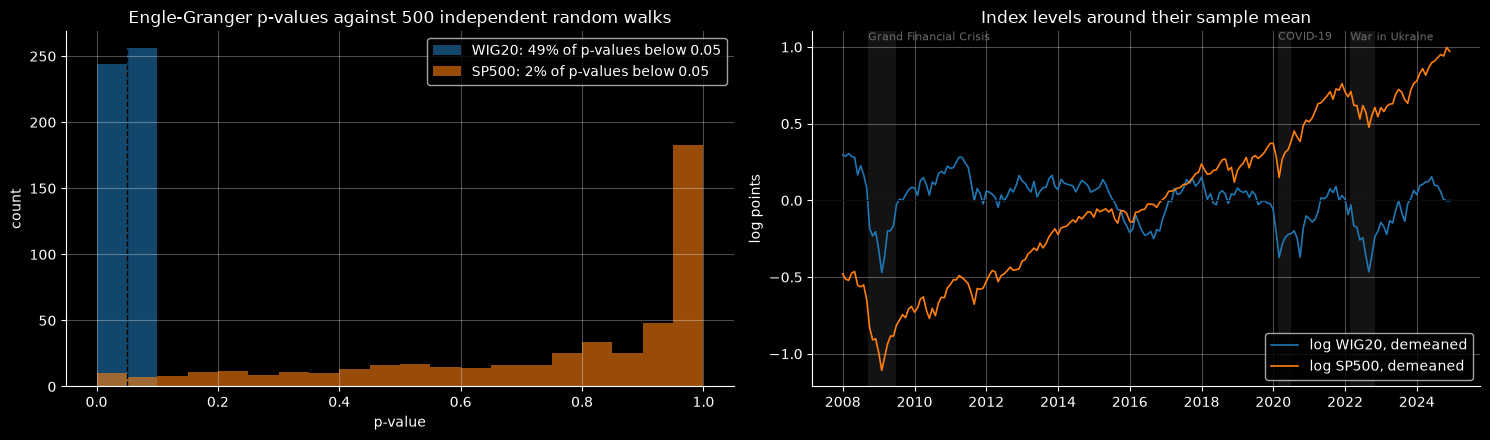

In [51]:
N_PLACEBO, rng = 500, np.random.default_rng(2024)

placebo_p = {}
for idx in ["WIG20", "SP500"]:
    y = m[idx].dropna().values
    placebo_p[idx] = np.array([coint(y, np.cumsum(rng.standard_normal(len(y))), trend="c", autolag="aic")[1]
                               for _ in range(N_PLACEBO)])
placebo = pd.DataFrame({f"EG rejects at {SIG_LABEL} vs random walk": {k: (v < SIGNIF).mean() for k, v in placebo_p.items()},
                        "nominal size": SIGNIF})
placebo.index.name = "index (monthly)"
display(placebo.style.format("{:.1%}"))

rows = []
for idx, own, other in [("WIG20", "PL", "US"), ("SP500", "US", "PL")]:
    for v in ["INFL", "UNEMP", "RATE", "EPU", "GDP"]:
        D = q if v == "GDP" else m
        for cc, kind in [(own, "own country"), (other, "other country (placebo)")]:
            if f"{v}_{cc}" in D:
                d = D[[idx, f"{v}_{cc}"]].dropna()
                rows.append({"index": idx, "variable": v, "source": kind,
                             "EG p": coint(d[idx], d[f"{v}_{cc}"], trend="c", autolag="aic")[1]})
cross = pd.DataFrame(rows).pivot_table(index=["index", "variable"], columns="source", values="EG p")
cross[f"placebo 'cointegrated' at {SIG_LABEL}"] = cross["other country (placebo)"] < SIGNIF
display(cross.style.format(precision=3))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for idx, color in [("WIG20", "tab:blue"), ("SP500", "tab:orange")]:
    axes[0].hist(placebo_p[idx], bins=20, range=(0, 1), alpha=0.6, color=color,
                 label=f"{idx}: {(placebo_p[idx] < SIGNIF).mean():.0%} of p-values below {SIGNIF}")
axes[0].axvline(SIGNIF, ls="--", color="black", lw=1)
axes[0].set(title=f"Engle-Granger p-values against {N_PLACEBO} independent random walks", xlabel="p-value", ylabel="count")
axes[0].legend()
for idx, color in [("WIG20", "tab:blue"), ("SP500", "tab:orange")]:
    x = m[idx].dropna()
    axes[1].plot(x.index, x - x.mean(), color=color, lw=1.2, label=f"log {idx}, demeaned")
axes[1].axhline(0, color="black", lw=0.6)
axes[1].set(title="Index levels around their sample mean", ylabel="log points", xlabel="")
axes[1].legend(loc="lower right"); shade_events(axes[1])
plt.tight_layout(); plt.savefig(FIG_DIR / "05_wig20_mean_reversion.png", dpi=150); plt.show()

### Johansen restriction test: does the relation reduce to WIG20 alone?

For each WIG20 pair, a two-variable VAR (lag length by BIC, as in Part D) is written in error-correction form with an unrestricted constant.

Let $S_{00}, S_{01}, S_{11}$ be the product-moment matrices of the Johansen (1988) reduced-rank regression. The largest eigenvalue $\hat\lambda_1$ solves the unrestricted problem. Fixing the cointegrating vector at $h = (1, 0)'$ gives

$$\lambda^* = \frac{h' S_{10} S_{00}^{-1} S_{01} h}{h' S_{11} h}, \qquad
LR = T \ln\frac{1 - \lambda^*}{1 - \hat\lambda_1} \sim \chi^2(1)$$

The verdict combines the LR test with the Johansen rank:

| Johansen rank | LR test of $\beta = (1, 0)'$ | Verdict |
| :--- | :--- | :--- |
| 0 | — | No cointegration (Johansen): no long-run relation in the system. |
| 2 (full rank) | — | Both series stationary: not cointegration in the usual sense. |
| 1 | Not rejected | Reduces to WIG20 alone: $x_t$ adds nothing to the relation. |
| 1 | Rejected | $x_t$ enters the long-run relation. |

The table also compares each pair's ECM half-life with WIG20's own AR(1) half-life. Similar values suggest that the "error correction" is mostly WIG20 reverting to its own mean.

In [52]:
def johansen_moments(Y, k_ar_diff):
    # Residual product moments of the Johansen reduced-rank regression with an unrestricted constant
    Y = np.asarray(Y, float); dY = np.diff(Y, axis=0)
    T = len(dY) - k_ar_diff
    Z = np.column_stack([np.ones((T, 1))] + [dY[k_ar_diff - j:len(dY) - j] for j in range(1, k_ar_diff + 1)])
    R0 = dY[k_ar_diff:] - Z @ np.linalg.lstsq(Z, dY[k_ar_diff:], rcond=None)[0]
    Y1 = Y[k_ar_diff:-1]
    R1 = Y1 - Z @ np.linalg.lstsq(Z, Y1, rcond=None)[0]
    return R0.T @ R0 / T, R0.T @ R1 / T, R1.T @ R1 / T, T

def index_stationarity_lr(d, k_ar_diff, var=0):
    # LR test of H0: the (single) cointegrating vector is the unit vector on column `var`
    S00, S01, S11, T = johansen_moments(d, k_ar_diff)
    S10 = S01.T
    lam = np.sort(np.linalg.eigvals(np.linalg.solve(S11, S10 @ np.linalg.solve(S00, S01))).real)[::-1]
    assert np.allclose(lam, np.sort(coint_johansen(d, det_order=0, k_ar_diff=k_ar_diff).eig)[::-1], atol=1e-6)
    h = np.zeros(S11.shape[0]); h[var] = 1
    lam_r = (h @ S10 @ np.linalg.solve(S00, S01) @ h) / (h @ S11 @ h)
    lr = T * np.log((1 - lam_r) / (1 - lam[0]))
    return lr, chi2.sf(lr, S11.shape[0] - 1)

own_hl = {"monthly": index_ur.loc[("monthly", "WIG20"), "own half-life"],
          "quarterly": ar1_half_life(q["WIG20"])[1],
          "weekly": index_ur.loc[("weekly", "WIG20"), "own half-life"]}
DATA_ALL = {**DATA, "weekly": w_logs}
WEEKLY_KEY = ("H3", "WIG20", "SP500_PLN (weekly)")
rows = []
for y, x, freq in [(y, x, f) for y, x, f in PAIRS if y == "WIG20"] + [("WIG20", "SP500_PLN", "weekly")]:
    d = DATA_ALL[freq][[y, x]].dropna()
    p = max(int(VAR(d).select_order(maxlags={"monthly": 6, "quarterly": 4, "weekly": 12}[freq]).selected_orders["bic"]), 2)
    r = select_coint_rank(d, det_order=0, k_ar_diff=p - 1, method="trace", signif=SIGNIF).rank
    lr, pv = index_stationarity_lr(d, p - 1)
    if r == 0:              verdict = "no cointegration (Johansen)"
    elif r == d.shape[1]:   verdict = "full rank: both series stationary"
    elif pv >= SIGNIF:      verdict = "reduces to WIG20 alone"
    else:                   verdict = f"{x} enters the relation"
    key = WEEKLY_KEY if freq == "weekly" else pair_key(y, x)
    rows.append(dict(zip(["hypothesis", "index", "variable"], key), freq=freq, **{
        "EG/GH result": compare.loc[key, "result"], "Johansen rank": r, "LR (β = [1, 0])": lr, "LR p": pv,
        "ECM half-life": ecm_tbl.loc[key, "half-life (periods)"] if key in ecm_tbl.index else np.nan,
        "WIG20 own half-life": own_hl[freq],
        "unit": {"monthly": "months", "quarterly": "quarters", "weekly": "weeks"}[freq], "verdict": verdict}))
wig20_check = pd.DataFrame(rows).set_index(["hypothesis", "index", "variable"])
display(wig20_check.style.format(precision=3))

coint_pairs = wig20_check[wig20_check["EG/GH result"] != "not cointegrated"]
n_info = int(coint_pairs["verdict"].str.endswith("enters the relation").sum())
display(Markdown(
    f"**Result:** WIG20 rejects a unit root in {sum(index_ur.loc[('monthly', 'WIG20'), f'{t} p (c)'] < SIGNIF for t in ('ADF', 'PP'))}"
    f" of 2 constant-only ADF/PP tests (monthly) and reverts to its mean with a half-life of about "
    f"{own_hl['monthly']:.0f} months. Against independent random walks, Engle-Granger reports cointegration in "
    f"{(placebo_p['WIG20'] < SIGNIF).mean():.0%} of draws for WIG20 and {(placebo_p['SP500'] < SIGNIF).mean():.0%} for the S&P 500. "
    f"Of the {len(coint_pairs)} WIG20 relationships classified as cointegrated in Parts A–C (including the weekly H3 pair), "
    f"the Johansen test finds that {n_info} involve the explanatory variable."))

**Result:** WIG20 rejects a unit root in 2 of 2 constant-only ADF/PP tests (monthly) and reverts to its mean with a half-life of about 7 months. Against independent random walks, Engle-Granger reports cointegration in 49% of draws for WIG20 and 2% for the S&P 500. Of the 8 WIG20 relationships classified as cointegrated in Parts A–C (including the weekly H3 pair), the Johansen test finds that 0 involve the explanatory variable.

### Implications for the hypotheses

* WIG20 lies between a unit root and slow mean reversion: ADF and Phillips-Perron (1988) with a constant reject the unit root, while DF-GLS, KPSS and Zivot-Andrews (1992) do not. Either way, as the random-walk placebo shows, the Engle-Granger (1987) test applied to WIG20 can hardly tell real long-run relations from unrelated regressors.
* A mean-reverting price index departs from the random-walk model behind weak-form efficiency (*Fama, 1970*). The random walk is rejected even for US weekly returns (*Lo & MacKinlay, 1999*), and weak-form efficiency is rejected more often for emerging than for developed markets (*Sharma & Mahendru, 2009*; *Ahmed et al., 2025*).
* For WIG20, H1–H3 cannot be confirmed with residual-based tests alone. A WIG20 pair counts as evidence only if the Johansen (1988) restriction test shows that the explanatory variable enters the long-run relation. Pairs that reduce to "WIG20 alone" are consistent with mean reversion whatever the macro variable.
* The S&P 500 results do not have this problem (the placebo rejection rate is close to or below the nominal size). They carry the opposite risk discussed in Section 5: the S&P 500 is close to trend-stationary, so models with a time trend (Gregory-Hansen (1996) C/T) need care.
* Two extensions follow. WIG20 could be tested as a total-return index (WIG20TR), which includes dividends and has a clearer stochastic trend. Bounds testing (ARDL) needs no prior decision on whether WIG20 is $I(0)$ or $I(1)$; Section 18 applies it.

## 18. ARDL bounds test (valid for I(0) and I(1) variables)

All earlier tests assume that the variables are $I(1)$, and Section 17 shows this is doubtful for WIG20. The ARDL bounds test (Pesaran, Shin & Smith, 2001; PSS) needs no such classification: its critical values come as two bounds, one for all regressors $I(0)$ and one for all $I(1)$.

For each pair, an ARDL($p$, $q$) model is selected by the Akaike Information Criterion (AIC; Akaike, 1974) and written in unrestricted error-correction form (UECM, PSS case 3: unrestricted constant, no trend):

$$\Delta y_t = c + \pi_y\, y_{t-1} + \pi_x\, x_{t-1} + \sum_{i=1}^{p-1}\phi_i \Delta y_{t-i} + \sum_{j=0}^{q-1}\theta_j \Delta x_{t-j} + \varepsilon_t,
\qquad \text{long-run coefficient } b = -\pi_x/\pi_y$$

### Three tests (McNown, Sam & Goh, 2018)

A long-run relation requires all three tests to reject:

| Test | Null hypothesis | Why it is needed |
| :--- | :--- | :--- |
| PSS F-test | $\pi_y = \pi_x = 0$ | The overall bounds test. It rejects if *either* lagged level matters. |
| PSS t-test on $\pi_y$ | $\pi_y = 0$ | Rules out degenerate case 1: a rejected F driven by $x_{t-1}$ alone, with no error correction. |
| Bootstrap test on $\pi_x$ | $\pi_x = 0$ | Rules out degenerate case 2: a rejected F driven by $y_{t-1}$ alone, meaning **the index is stationary on its own**, which is exactly the WIG20 problem. The $t$-statistic has a non-standard distribution, so its p-value is bootstrapped under $H_0$ from the restricted UECM with resampled residuals. |

For the F- and t-tests, a statistic beyond the $I(1)$ bound rejects the null, one within the $I(0)$ bound does not, and one in between is inconclusive.

### Critical values

In `statsmodels` 0.15, `UECMResults.bounds_test` looks up the PSS table with the number of variables *including* the dependent variable ($k = 2$ for one regressor), but the PSS tables are indexed by the number of regressors ($k = 1$). The test statistic is correct, but the 5% critical values are too low (3.80 / 4.81 instead of about 4.9 / 5.7; PSS publish 4.94 / 5.73), so the test over-rejects. The cell below reports both sets of bounds and uses the $k = 1$ row of the same `statsmodels` table. A separate Monte Carlo simulation (20,000 draws, $T = 1000$) gives 95th percentiles of 4.94 ($I(0)$ regressor) and 5.77 ($I(1)$ regressor), which confirms the $k = 1$ values.

In [53]:
# PSS (2001) Table CII(iii), case 3, k = 1: t-bounds (I(0), I(1)) for π_y
PSS_T = {0.10: (-2.57, -2.91), 0.05: (-2.86, -3.22), 0.01: (-3.43, -3.82)}
PSS_PCT = list(pss_critical_values.crit_percentiles).index(round(100 * (1 - SIGNIF), 1))
N_BOOT, ARDL_MAXLAG = 1999, {"monthly": 6, "quarterly": 4, "weekly": 8}
try:    # private statsmodels helper: p-values from the same simulated PSS distribution
    from statsmodels.tsa.ardl.model import _pss_pvalue
except ImportError:     # fallback if a future statsmodels removes it: interpolate the tabulated percentiles
    def _pss_pvalue(stat, k, case, i1):
        return float(1 - np.interp(stat, pss_critical_values.crit_vals[(k, case, i1)],
                                   np.asarray(pss_critical_values.crit_percentiles) / 100))

def pss_f_bounds(k):
    return tuple(pss_critical_values.crit_vals[(k, 3, upper)][PSS_PCT] for upper in (False, True))

def uecm_design(y, x, p, q):
    # Δy_t on [1, y_{t-1}, x_{t-1}, Δy_{t-1..t-p+1}, Δx_{t..t-q+1}]: the same design as statsmodels' UECM
    y, x = np.asarray(y, float), np.asarray(x, float)
    dy, dx = np.diff(y, prepend=np.nan), np.diff(x, prepend=np.nan)
    X = np.column_stack([np.ones_like(y), np.roll(y, 1), np.roll(x, 1)]
                        + [np.roll(dy, i) for i in range(1, p)] + [np.roll(dx, j) for j in range(q)])
    start = max(p, q)
    return dy[start:], X[start:]

def ols_fit(yv, X):
    b = np.linalg.lstsq(X, yv, rcond=None)[0]
    e = yv - X @ b
    return b, e, (e @ e / (len(yv) - X.shape[1])) * np.linalg.inv(X.T @ X)

def x_level_bootstrap(y, x, p, q, n_boot, rng):
    # Bootstrap p-value of |t| on π_x under H0: π_x = 0 (McNown, Sam & Goh, 2018); x is held fixed
    dyv, X = uecm_design(y, x, p, q)
    b, _, V = ols_fit(dyv, X)
    t_obs = b[2] / np.sqrt(V[2, 2])
    br, er, _ = ols_fit(dyv, np.delete(X, 2, axis=1))
    er = er - er.mean()
    dx, start = np.diff(x, prepend=np.nan), max(p, q)
    t_star = np.empty(n_boot)
    for r in range(n_boot):
        ys = y.copy(); dys = np.diff(ys, prepend=np.nan)
        eps = rng.choice(er, size=len(y) - start)
        for t in range(start, len(y)):
            row = [1.0, ys[t - 1]] + [dys[t - i] for i in range(1, p)] + [dx[t - j] for j in range(q)]
            dys[t] = br @ row + eps[t - start]
            ys[t] = ys[t - 1] + dys[t]
        b2, _, V2 = ols_fit(*uecm_design(ys, x, p, q))
        t_star[r] = b2[2] / np.sqrt(V2[2, 2])
    return t_obs, float(np.mean(np.abs(t_star) >= abs(t_obs)))

def ardl_bounds(d, y, x, maxlag, n_boot=N_BOOT, seed=0):
    d = d[[y, x]].dropna().reset_index(drop=True)
    order = ardl_select_order(d[y], maxlag, d[[x]], maxlag, ic="aic", trend="c").model.ardl_order
    p, q = max(order[0], 1), max(order[1] if len(order) > 1 else 0, 1)   # UECM needs at least one lag of each
    res = UECM(d[y], p, d[[x]], {x: q}, trend="c").fit()
    dyv, X = uecm_design(d[y], d[x], p, q)
    assert np.allclose(ols_fit(dyv, X)[0], res.params.values, atol=1e-8), "UECM design mismatch"
    F = res.bounds_test(case=3).statistic
    F_lo, F_hi = pss_f_bounds(1)
    pF_lo, pF_hi = _pss_pvalue(F, 1, 3, False), _pss_pvalue(F, 1, 3, True)
    t_y, (t_lo, t_hi) = res.tvalues[f"{y}.L1"], PSS_T[SIGNIF]
    t_x, p_x = x_level_bootstrap(d[y].values, d[x].values, p, q, n_boot, np.random.default_rng(seed))
    if pF_lo >= SIGNIF:     verdict = "no long-run relation"
    elif pF_hi >= SIGNIF:   verdict = "inconclusive (F between bounds)"
    elif t_y > t_lo:        verdict = "degenerate: no error correction"
    elif t_y > t_hi:        verdict = "inconclusive (t between bounds)"
    elif p_x >= SIGNIF:     verdict = "degenerate: index stationary on its own"
    else:                   verdict = "long-run relation"
    return {"ARDL (p, q)": f"({p}, {q})", "n": len(d), "F": F, f"F {SIG_LABEL} bounds": f"{F_lo:.2f} / {F_hi:.2f}",
            "F p (I(1) bound)": pF_hi, "t on y(t-1)": t_y, f"t {SIG_LABEL} bounds": f"{t_lo} / {t_hi}",
            "t on x(t-1)": t_x, "bootstrap p (x level)": p_x, "long-run b": res.ci_params[x] * -1,
            "adjustment speed": res.params[f"{y}.L1"], "verdict": verdict}

lo2, hi2 = pss_f_bounds(2); lo1, hi1 = pss_f_bounds(1)
print(f"PSS case 3 F-bounds at {SIG_LABEL}: statsmodels bounds_test (k = 2) {lo2:.2f} / {hi2:.2f}; "
      f"correct for one regressor (k = 1) {lo1:.2f} / {hi1:.2f}")

rows = []
for y, x, freq in PAIRS + [("WIG20", "SP500_PLN", "weekly")]:
    key = ("H3", "WIG20", "SP500_PLN (weekly)") if freq == "weekly" else pair_key(y, x)
    rows.append(dict(zip(["hypothesis", "index", "variable"], key), freq=freq,
                     **ardl_bounds(DATA_ALL[freq], y, x, ARDL_MAXLAG[freq], seed=len(rows))))
ardl_tbl = pd.DataFrame(rows).set_index(["hypothesis", "index", "variable"])
display(ardl_tbl.style.format(precision=3))

counts = {idx: (int((sub["verdict"] == "long-run relation").sum()), len(sub)) for idx, sub in ardl_tbl.groupby(level="index")}
display(Markdown(f"**ARDL result:** the ARDL test finds a long-run relation that involves the explanatory variable in "
                 f"{counts['WIG20'][0]} of {counts['WIG20'][1]} WIG20 pairs and {counts['SP500'][0]} of {counts['SP500'][1]} "
                 f"S&P 500 pairs. In {int((ardl_tbl['verdict'] == 'degenerate: index stationary on its own').sum())} pairs "
                 f"the index is stationary on its own (degenerate case)."))

PSS case 3 F-bounds at 5%: statsmodels bounds_test (k = 2) 3.80 / 4.81; correct for one regressor (k = 1) 4.92 / 5.72


**ARDL result:** the ARDL test finds a long-run relation that involves the explanatory variable in 2 of 8 WIG20 pairs and 0 of 5 S&P 500 pairs. In 6 pairs the index is stationary on its own (degenerate case).

### Size check: the ARDL procedure on placebo data

The random-walk placebo from Section 17 is repeated with the full ARDL procedure: WIG20 against `N_ARDL_PLACEBO` independent random walks. Engle-Granger (1987) found "cointegration" in about half of these draws. A correctly sized procedure should report a long-run relation in about `SIGNIF` of them and classify the rest as no relation or as WIG20 being stationary on its own. To keep the run short, this check uses 199 bootstrap replications instead of the full number.

In [54]:
N_ARDL_PLACEBO, rng_pl = 100, np.random.default_rng(99)
pl = pd.Series([ardl_bounds(pd.DataFrame({"WIG20": m["WIG20"].values,
                                          "RW": np.cumsum(rng_pl.standard_normal(len(m)))}),
                            "WIG20", "RW", ARDL_MAXLAG["monthly"], n_boot=199, seed=i)["verdict"]
                for i in range(N_ARDL_PLACEBO)])
ardl_placebo = pl.value_counts(normalize=True).rename("share of placebo draws").to_frame()
display(ardl_placebo.style.format("{:.0%}"))
print(f"False 'long-run relation' rate: {(pl == 'long-run relation').mean():.0%} (nominal {SIGNIF:.0%}); "
      f"Engle-Granger on the same kind of placebo: {(placebo_p['WIG20'] < SIGNIF).mean():.0%}")

,share of placebo draws
degenerate: index stationary on its own,92%
long-run relation,8%


False 'long-run relation' rate: 8% (nominal 5%); Engle-Granger on the same kind of placebo: 49%


### Reading the ARDL results

* On its own, the F-test would confirm almost every WIG20 pair. It rejects because WIG20's own lagged level is significant, which is the mean reversion found in Section 17, not a long-run link to the macro variable.
* The bootstrap test on $x_{t-1}$ separates the two cases. Pairs marked *degenerate: index stationary on its own* carry no evidence about the macro variable, however large their F-statistic.
* Pairs that pass all three tests still need care. Their bootstrap p-values are close to the significance level, about a dozen pairs are tested (so roughly one false positive is expected at 5%), and a long-run coefficient needs an economically plausible sign before it counts as support for H1–H3.
* The literature expects policy uncertainty to lower stock prices (*Antonakakis, Chatziantoniou & Filis, 2013*; *Yıldırım & Ince-Yenilmez, 2025*). The sign of the unemployment relation differs across markets: positive for the UK and negative for Japan (*Wiśniewski, 2014*).
* For the S&P 500, the ARDL test agrees with Engle-Granger (1987) on real GDP and the macro variables: there is no long-run relation in levels unless a structural break is allowed.

## 19. Summary of results

The table below has one row per relationship and sets the naive OLS result against the cointegration tests:

* **Naive OLS significant:** whether the levels regression from Section 6 gives $|t| > 1.96$.
* **Engle-Granger** (1987; Part A) and **Gregory-Hansen** (1996; Part B): cointegration under each test, with the estimated break date $\hat{\tau}$ for pairs cointegrated under Gregory-Hansen.
* **Long-run b:** the coefficient from the long-run regression (an elasticity for log-log pairs).
* **Cointegrated:** cointegrated under Engle-Granger or Gregory-Hansen.
* **Spurious in OLS:** significant in the naive regression but not cointegrated under either test.
* **ECM half-life:** periods needed to close half of a deviation from equilibrium (Sections 8 and 11).
* **WIG20 check:** for WIG20 pairs, the Johansen (1988) verdict from Section 17, i.e. whether the relation involves the variable or reduces to WIG20 alone.
* **ARDL:** the bounds-test verdict from Section 18, valid whether the variables are I(0) or I(1).

A final table gives the verdict for H1–H3, including the weekly Johansen rank and the Granger (1969) causality results for H3.
The detailed statistics are in the earlier sections: $R^2$, $t$-statistics and Durbin-Watson (1950) in Section 6, the Gregory-Hansen
models in Section 10, the four groups in Section 13, the VECM adjustment coefficients $\alpha$ in Sections 14–15,
the WIG20 mean-reversion diagnostics in Section 17 and the ARDL bounds tests in Section 18.

In [55]:
summary = pd.DataFrame({
    "naive OLS significant": naive["t-stat (naive)"].abs() > T_CRIT,
    "Engle-Granger": eg_tbl["EG cointegrated"],
    "Gregory-Hansen": gh_tbl["GH cointegrated"],
    "GH break": gh_tbl["break date"].where(gh_tbl["GH cointegrated"], ""),
    "long-run b": eg_tbl["b (long-run)"],
})
summary["cointegrated"] = summary["Engle-Granger"] | summary["Gregory-Hansen"]
summary["spurious in OLS"] = summary["naive OLS significant"] & ~summary["cointegrated"]
if not ecm_tbl.empty:
    summary["ECM half-life"] = ecm_tbl["half-life (periods)"].astype(float).round(1)
summary["WIG20 check"] = wig20_check["verdict"].reindex(summary.index).fillna("")
summary["ARDL"] = ardl_tbl["verdict"].reindex(summary.index)
display(summary)

def verdict(sub):
    if sub.empty: return "not tested (data missing)"
    hits = [f"{v}{' (break ' + b + ')' if not e and g else ''}"
            for (_, _, v), e, g, b in zip(sub.index, sub["Engle-Granger"], sub["Gregory-Hansen"], sub["GH break"])
            if e or g]
    text = f"{len(hits)}/{len(sub)} cointegrated" + (f": {', '.join(hits)}" if hits else "")
    checked = sub[(sub["Engle-Granger"] | sub["Gregory-Hansen"]) & (sub["WIG20 check"] != "")]
    if len(checked):    # WIG20 pairs: how many survive the Johansen check of Section 17
        text += f"; Johansen check: {int(checked['WIG20 check'].str.endswith('enters the relation').sum())} involve the variable"
    return text

lines = ["| Hypothesis | WIG20 (Poland) | S&P 500 (USA) |", "|---|---|---|"]
for h, label in [("H1", "H1: macro variables"), ("H2", "H2: policy uncertainty")]:
    sub = summary.xs(h, level="hypothesis", drop_level=False) if h in summary.index.get_level_values(0) else summary.iloc[0:0]
    cells = [verdict(sub[sub.index.get_level_values("index") == i]) for i in ["WIG20", "SP500"]]
    lines.append(f"| {label} | {cells[0]} | {cells[1]} |")
gh_w_txt = (f"significant ({gh_w_best}, break {gh_w[gh_w_best]['break']:%Y-%m})" if gh_w[gh_w_best]["significant"]
            else "not significant")
lines.append(f"| H3: emerging ↔ developed (weekly) | Johansen rank r = {rank}; EG p = {eg_w:.3f}; GH {gh_w_txt}; "
             f"Granger: {', '.join(granger.index[granger['significant']]) or 'none'} | — |")
n_spur = int(summary["spurious in OLS"].sum())
wig_coint = summary[(summary.index.get_level_values("index") == "WIG20") & summary["cointegrated"]]
n_wig_info = int(wig_coint["WIG20 check"].str.endswith("enters the relation").sum())
lines += ["", f"**Spurious regression:** {n_spur} of {len(summary)} relationships are significant in a naive levels "
              f"regression but are not cointegrated.",
          "", f"**WIG20 mean reversion (Section 17):** only {n_wig_info} of {len(wig_coint)} cointegrated monthly and quarterly WIG20 relationships "
              f"involve the explanatory variable; the rest are consistent with WIG20 reverting to its own mean.",
          "", f"**ARDL bounds test (Section 18):** long-run relation in {counts['WIG20'][0]} of {counts['WIG20'][1]} WIG20 pairs "
              f"and {counts['SP500'][0]} of {counts['SP500'][1]} S&P 500 pairs (including the weekly H3 pair)."]
display(Markdown("\n".join(lines)))

naive OLS significant  Engle-Granger  \
hypothesis index variable                                         
H1         SP500 GDP_US                     True          False   
                 INFL_US                    True          False   
                 RATE_US                    True          False   
                 UNEMP_US                   True          False   
           WIG20 GDP_PL                     True           True   
                 INFL_PL                    True           True   
                 RATE_PL                   False          False   
                 UNEMP_PL                   True           True   
H2         SP500 EPU_US                     True          False   
           WIG20 EPU_PL                     True           True   
H3         WIG20 SP500                      True           True   
                 USDPLN                     True           True   

                           Gregory-Hansen GH break  long-run b  cointegrated  \
hypothesis index variable                                                      
H1         SP500 GDP_US              True  2020-10      4.6352          True   
                 INFL_US            False               0.1206         False   
                 RATE_US            False               0.1847         False   
                 UNEMP_US           False              -0.1589         False   
           WIG20 GDP_PL              True  2015-07     -0.2928          True   
                 INFL_PL            False              -0.0124          True   
                 RATE_PL             True  2019-03      0.0058          True   
                 UNEMP_PL            True  2017-07      0.0196          True   
H2         SP500 EPU_US              True  2022-02      0.3474          True   
           WIG20 EPU_PL              True  2014-10     -0.1909          True   
H3         WIG20 SP500               True  2010-07     -0.0646          True   
                 USDPLN              True  2011-01     -0.5891          True   

                           spurious in OLS  ECM half-life  \
hypothesis index variable                                   
H1         SP500 GDP_US              False         1.4000   
                 INFL_US              True            NaN   
                 RATE_US              True            NaN   
                 UNEMP_US             True            NaN   
           WIG20 GDP_PL              False         1.2000   
                 INFL_PL             False         6.0000   
                 RATE_PL             False         6.1000   
                 UNEMP_PL            False         5.3000   
H2         SP500 EPU_US              False         4.3000   
           WIG20 EPU_PL              False         4.9000   
H3         WIG20 SP500               False         9.7000   
                 USDPLN              False         6.9000   

                                                 WIG20 check  \
hypothesis index variable                                      
H1         SP500 GDP_US                                        
                 INFL_US                                       
                 RATE_US                                       
                 UNEMP_US                                      
           WIG20 GDP_PL               reduces to WIG20 alone   
                 INFL_PL              reduces to WIG20 alone   
                 RATE_PL         no cointegration (Johansen)   
                 UNEMP_PL             reduces to WIG20 alone   
H2         SP500 EPU_US                                        
           WIG20 EPU_PL    full rank: both series stationary   
H3         WIG20 SP500           no cointegration (Johansen)   
                 USDPLN    full rank: both series stationary   

                                                              ARDL  
hypothesis index variable                                           
H1         SP500 GDP_US                       no long-run relation  
        

| Hypothesis | WIG20 (Poland) | S&P 500 (USA) |
|---|---|---|
| H1: macro variables | 4/4 cointegrated: GDP_PL, INFL_PL, RATE_PL (break 2019-03), UNEMP_PL; Johansen check: 0 involve the variable | 1/4 cointegrated: GDP_US (break 2020-10) |
| H2: policy uncertainty | 1/1 cointegrated: EPU_PL; Johansen check: 0 involve the variable | 1/1 cointegrated: EPU_US (break 2022-02) |
| H3: emerging ↔ developed (weekly) | Johansen rank r = 1; EG p = 0.012; GH not significant; Granger: SP500_PLN → WIG20, WIG20 → USDPLN | — |

**Spurious regression:** 3 of 12 relationships are significant in a naive levels regression but are not cointegrated.

**WIG20 mean reversion (Section 17):** only 0 of 7 cointegrated monthly and quarterly WIG20 relationships involve the explanatory variable; the rest are consistent with WIG20 reverting to its own mean.

**ARDL bounds test (Section 18):** long-run relation in 2 of 8 WIG20 pairs and 0 of 5 S&P 500 pairs (including the weekly H3 pair).

### Interpretation notes and limitations

* **Spurious regression:** naive regressions in levels often give a high $R^2$ and "significant" $t$-statistics. Long-run interpretations hold only for pairs confirmed as cointegrated.
* **WIG20 mean reversion:** WIG20 has no trend over 2008–2024 and is borderline stationary (Section 17). Engle-Granger (1987) and Gregory-Hansen (1996) results for WIG20 pairs therefore say little unless the Johansen (1988) restriction test shows that the explanatory variable enters the relation.
* **ARDL bounds test:** valid for I(0) and I(1) variables but not for I(2) ones. The bootstrap for the long-run role of $x$ holds the regressor fixed and resamples residuals i.i.d.; p-values close to the significance level can move by about ±0.01 with a different seed. The PSS critical values are asymptotic, which matters most for the quarterly GDP pairs ($n = 68$).
* **Integration order:** cointegration requires both variables to be $I(1)$. A stationary, $I(0)$, regressor cannot share a cointegrating vector with a trending index, so the unit-root results decide which pairs are tested.
* **One break only:** the Gregory-Hansen test allows exactly one structural break, so relationships that changed several times may still be missed. The estimated break date is the most likely single shift, not proof that a particular event caused it.
* **Multiple testing:** about 12 pairs are tested with several procedures, so some type I errors are expected; borderline results ($p \approx 0.03\text{--}0.06$) should be read with caution.
* **GDP measurement:** GDP is real (constant prices) and seasonally adjusted, from Eurostat (Poland, chain-linked 2010 PLN) and FRED/BEA (US, chained 2017 USD). The indices are nominal price indices, so the GDP elasticity mixes a real regressor with a nominal regressand; a deflated index would make the pair fully real. National accounts are revised, so a new download may change the last few quarters slightly.
* **Price vs. total-return indices:** the indices are price indices and exclude reinvested dividends. Total-return indices would change the long-run drift and the estimated coefficients.
* **FX timing:** the NBP exchange rate is the daily reference fixing (about 11:45 Warsaw time), not the rate at the equity market close, so there is a small intraday timing mismatch.
* **Deterministic specification:** each Johansen system has at least one long-run relation under every deterministic specification (Section 16; *Johansen, 1991*), but the number of relations changes. The second Polish relation and the weekly H3 relation are borderline. An approximate LR test supports a linear trend for the US and weekly H3 systems but not for Poland; for H3 the trend specification gives full rank, which contradicts the $I(1)$ results, so the constant-only specification is used throughout.
* **One significance level:** every test decision uses `SIGNIF = 0.05` (Section 1, configuration): unit-root classification, the Engle-Granger, Gregory-Hansen and Johansen critical values, Granger (1969) causality, the naive-OLS $|t|$ cutoff and the significance flags on ECM $\gamma$ and VECM $\alpha$. KPSS p-values shown as 0.10 or 0.01 are table bounds (see Section 5).
* **Reproducibility:** the results were produced with the project's `.venv` and `requirements.txt` (`statsmodels` pinned below 0.16, whose test functions change their return format). Always run *Kernel → Restart Kernel and Run All*: later sections use variables created earlier (e.g. the monthly log dataset `m` from Section 4), so running single cells after a restart fails.

## 20. Export

In [56]:
Path("output").mkdir(exist_ok=True)
monthly.to_csv("output/monthly_dataset.csv"); q.to_csv("output/quarterly_dataset_log.csv"); weekly.to_csv("output/weekly_dataset.csv")
with pd.ExcelWriter("output/results.xlsx") as xw:
    summary.to_excel(xw, sheet_name="summary")
    ur.to_excel(xw, sheet_name="unit_root")
    naive.to_excel(xw, sheet_name="naive_levels_OLS")
    eg_tbl.to_excel(xw, sheet_name="engle_granger")
    gh_tbl.to_excel(xw, sheet_name="gregory_hansen")
    compare.to_excel(xw, sheet_name="EG_vs_GH")
    jo_tbl.to_excel(xw, sheet_name="johansen_by_country")
    for idx, v in vecm_tbls.items(): v.to_excel(xw, sheet_name=f"VECM_{idx}")
    if not ecm_tbl.empty: ecm_tbl.to_excel(xw, sheet_name="ECM")
    johansen.to_excel(xw, sheet_name="H3_johansen"); granger.to_excel(xw, sheet_name="H3_granger")
    det_robust.to_excel(xw, sheet_name="robust_deterministic"); trend_lr.to_excel(xw, sheet_name="robust_trend_LR")
    index_ur.to_excel(xw, sheet_name="index_unit_root_battery"); placebo.to_excel(xw, sheet_name="placebo_random_walk")
    cross.to_excel(xw, sheet_name="placebo_cross_country"); wig20_check.to_excel(xw, sheet_name="WIG20_stationarity_LR")
    ardl_tbl.to_excel(xw, sheet_name="ARDL_bounds"); ardl_placebo.to_excel(xw, sheet_name="ARDL_placebo")
!rm -f results.zip && zip -qr results.zip output data   # rebuild, so deleted files don't linger
print("Saved results.zip: datasets, raw API cache, figures and all result tables")

Saved results.zip: datasets, raw API cache, figures and all result tables


## References

### Empirical and theoretical literature

* Aggarwal, R., Inclan, C., & Leal, R. (1999). Volatility in Emerging Stock Markets. *The Journal of Financial and Quantitative Analysis*, 34(1), 33–55.
* Ahmed, B., Dawood, M. N., Abrar, A., Waheed, M., & Bibi, N. (2025). Analyzing the Financial Markets Pulse: Efficiency, Asset Pricing, and Behavioral Insights in Developed and Emerging Economies. *International Journal of Business and Management Sciences*, 6(1), 525–541.
* Antonakakis, N., Chatziantoniou, I., & Filis, G. (2013). Dynamic co-movements of stock market returns, implied volatility and policy uncertainty. *Economics Letters*, 120(1), 87–92.
* Bernanke, B. S., & Kuttner, K. N. (2005). What Explains the Stock Market's Reaction to Federal Reserve Policy? *The Journal of Finance*, 60(3), 1221–1257.
* Chen, N.-F., Roll, R., & Ross, S. A. (1986). Economic Forces and the Stock Market. *The Journal of Business*, 59(3), 383–403.
* Fama, E. F. (1970). Efficient Capital Markets: A Review of Theory and Empirical Work. *The Journal of Finance*, 25(2), 383–417.
* Fama, E. F., & Schwert, G. W. (1977). Asset Returns and Inflation. *Journal of Financial Economics*, 5(2), 115–146.
* Lo, A. W., & MacKinlay, A. C. (1999). *A Non-Random Walk Down Wall Street*. Princeton University Press.
* Muradoglu, G., Taskin, F., & Bigan, I. (2000). Causality between Stock Returns and Macroeconomic Variables in Emerging Markets. *Russian & East European Finance and Trade*, 36(6), 33–53.
* Panda, C. (2008). Do Interest Rates Matter for Stock Markets? *Economic and Political Weekly*, 43, 107–115.
* Sarwar, G., & Khan, W. (2017). The Effect of US Stock Market Uncertainty on Emerging Market Returns. *Emerging Markets Finance and Trade*, 53(8), 1796–1811.
* Sharma, G., & Mahendru, M. (2009). Efficiency Hypothesis of the Stock Markets: A Case of Indian Securities. *International Journal of Business and Management*, 4, 136.
* Wiśniewski, H. (2014). *Wpływ zmiennych makroekonomicznych na indeksy giełdowe* [The impact of macroeconomic variables on stock market indices]. Doctoral dissertation, Faculty of Economic Sciences, University of Warsaw.
* Yıldırım, H., & Ince-Yenilmez, M. (2025). The relationship of economic policy uncertainty with the stock market index and the exchange rate: The case of Russia. *Journal of New Economy*, 26(1), 69–86.

### Econometric methods

* Akaike, H. (1974). A New Look at the Statistical Model Identification. *IEEE Transactions on Automatic Control*, 19(6), 716–723.
* Dickey, D. A., & Fuller, W. A. (1979). Distribution of the Estimators for Autoregressive Time Series with a Unit Root. *Journal of the American Statistical Association*, 74(366), 427–431.
* Durbin, J., & Watson, G. S. (1950). Testing for Serial Correlation in Least Squares Regression: I. *Biometrika*, 37(3/4), 409–428.
* Elliott, G., Rothenberg, T. J., & Stock, J. H. (1996). Efficient Tests for an Autoregressive Unit Root. *Econometrica*, 64(4), 813–836.
* Engle, R. F., & Granger, C. W. J. (1987). Co-Integration and Error Correction: Representation, Estimation, and Testing. *Econometrica*, 55(2), 251–276.
* Granger, C. W. J. (1969). Investigating Causal Relations by Econometric Models and Cross-Spectral Methods. *Econometrica*, 37(3), 424–438.
* Granger, C. W. J., & Newbold, P. (1974). Spurious Regressions in Econometrics. *Journal of Econometrics*, 2(2), 111–120.
* Gregory, A. W., & Hansen, B. E. (1996). Residual-Based Tests for Cointegration in Models with Regime Shifts. *Journal of Econometrics*, 70(1), 99–126.
* Johansen, S. (1988). Statistical Analysis of Cointegration Vectors. *Journal of Economic Dynamics and Control*, 12(2–3), 231–254.
* Johansen, S. (1991). Estimation and Hypothesis Testing of Cointegration Vectors in Gaussian Vector Autoregressive Models. *Econometrica*, 59(6), 1551–1580.
* Johansen, S., & Juselius, K. (1992). Testing Structural Hypotheses in a Multivariate Cointegration Analysis of the PPP and the UIP for UK. *Journal of Econometrics*, 53(1–3), 211–244.
* Kwiatkowski, D., Phillips, P. C. B., Schmidt, P., & Shin, Y. (1992). Testing the Null Hypothesis of Stationarity Against the Alternative of a Unit Root. *Journal of Econometrics*, 54(1–3), 159–178.
* MacKinnon, J. G. (2010). Critical Values for Cointegration Tests. *Queen's Economics Department Working Paper* No. 1227, Queen's University.
* McNown, R., Sam, C. Y., & Goh, S. K. (2018). Bootstrapping the Autoregressive Distributed Lag Test for Cointegration. *Applied Economics*, 50(13), 1509–1521.
* Newey, W. K., & West, K. D. (1987). A Simple, Positive Semi-Definite, Heteroskedasticity and Autocorrelation Consistent Covariance Matrix. *Econometrica*, 55(3), 703–708.
* Pesaran, M. H., Shin, Y., & Smith, R. J. (2001). Bounds Testing Approaches to the Analysis of Level Relationships. *Journal of Applied Econometrics*, 16(3), 289–326.
* Phillips, P. C. B., & Perron, P. (1988). Testing for a Unit Root in Time Series Regression. *Biometrika*, 75(2), 335–346.
* Zivot, E., & Andrews, D. W. K. (1992). Further Evidence on the Great Crash, the Oil-Price Shock, and the Unit-Root Hypothesis. *Journal of Business & Economic Statistics*, 10(3), 251–270.

### Data sources and market classification

* Baker, S. R., Bloom, N., & Davis, S. J. (2016). Measuring Economic Policy Uncertainty. *The Quarterly Journal of Economics*, 131(4), 1593–1636. Data: [policyuncertainty.com](https://www.policyuncertainty.com).
* Białkowski, J. P., Klepka, R., & Sławik, A. (2025). Local and External Economic Policy Uncertainty and Their Impact on Exchange Rates in Emerging Markets: Evidence from Poland. *SSRN Working Paper* No. 5104696. https://doi.org/10.2139/ssrn.5104696. Data ("EPU POLAND LONG", 2003–2024): [policyuncertainty.com/poland_monthly.html](https://www.policyuncertainty.com/poland_monthly.html).
* Eurostat, *Quarterly national accounts: GDP and main components* (`namq_10_gdp`); Federal Reserve Bank of St. Louis, FRED series `GDPC1` and `FEDFUNDS`; National Bank of Poland, Table A exchange rates and reference rate; Stooq.
* Giełda Papierów Wartościowych w Warszawie: [Poland developed market](https://www.gpw.pl/Polanddevelopedmarket) (FTSE Russell reclassification).
* MSCI: [Market classification](https://www.msci.com/documents/10199/c0db0a48-01f2-4ba9-ad01-226fd5678111).